# 6BUIS017W CWK1 — Market Analysis and Stock Segmentation Using RFM

In [1]:
!git clone https://github.com/aaisha-aamina/crm-sp500-rfm-segmentation
%cd crm-sp500-rfm-segmentation

Cloning into 'crm-sp500-rfm-segmentation'...
remote: Enumerating objects: 103, done.
remote: Counting objects: 100% (103/103), done.
remote: Compressing objects: 100% (99/99), done.
remote: Total 103 (delta 44), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (103/103), 16.67 MiB | 21.21 MiB/s, done.
Resolving deltas: 100% (44/44), done.
/content/crm-sp500-rfm-segmentation


# Task 1 — Data Preparation and Feature Engineering
## Setup and configuration
`USE_SNAPSHOT = True` makes the notebook read only the saved files in `data/`. Set it to `False` **only** to repeat the one-off download (this would overwrite the snapshot and can change results, because adjusted prices and the constituent list are revised over time).

In [2]:
import io, json, sys, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import yfinance as yf

START, END = '2021-01-01', '2025-01-01'     # END is exclusive
BENCH = '^GSPC'
USE_SNAPSHOT = True    # False = download now; True = only read saved files (use this on all later runs)

DATA_DIR = Path('data'); DATA_DIR.mkdir(exist_ok=True)
F_CONST  = DATA_DIR / 'sp500_constituents.csv'
F_HTML   = DATA_DIR / 'sp500_wikipedia_snapshot.html'
F_PRICES = DATA_DIR / 'raw_prices_long.csv.gz'
F_META   = DATA_DIR / 'metadata.json'

versions = {'python': sys.version.split()[0], 'pandas': pd.__version__,
            'numpy': np.__version__, 'yfinance': yf.__version__}
print(versions)

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66'}


## 1.1 Ticker selection and data acquisition
* **Ticker list:** current S&P 500 constituents read from Wikipedia with `pandas.read_html`; the retrieval date is stored in `metadata.json`. Wikipedia writes share classes as `BRK.B`; Yahoo uses `BRK-B`, so dots are replaced by hyphens.
* **Price source (documented choice):** `yfinance` (Yahoo Finance) for daily Open, High, Low, Close, Adjusted Close and Volume, with `auto_adjust=False` so that raw Close (needed for Monetary) and Adjusted Close (needed for returns) are both kept. The benchmark is `^GSPC`.
* **Period:** 1 Jan 2021 to 1 Jan 2025, end date exclusive.

In [3]:
WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

if USE_SNAPSHOT:
    cons = pd.read_csv(F_CONST)
    meta = json.loads(F_META.read_text())
else:
    r = requests.get(WIKI_URL, headers={'User-Agent': 'Mozilla/5.0 (university coursework 6BUIS017W)'}, timeout=30)
    r.raise_for_status()
    F_HTML.write_text(r.text, encoding='utf-8')
    cons = pd.read_html(io.StringIO(r.text))[0]
    # Wikipedia writes BRK.B, Yahoo writes BRK-B
    cons['yf_ticker'] = cons['Symbol'].astype(str).str.strip().str.replace('.', '-', regex=False)
    cons.to_csv(F_CONST, index=False)
    now = datetime.now(timezone.utc)
    meta = {'wikipedia_url': WIKI_URL,
            'retrieval_date_utc': str(now.date()),
            'retrieval_timestamp_utc': now.isoformat(timespec='seconds'),
            'price_source': 'yfinance (auto_adjust=False)',
            'versions': versions, 'start': START, 'end_exclusive': END, 'benchmark': BENCH}
    F_META.write_text(json.dumps(meta, indent=2))

assert not cons['yf_ticker'].duplicated().any()
print(len(cons), 'tickers | retrieved:', meta['retrieval_date_utc'])
cons[['Symbol', 'yf_ticker', 'Security', 'GICS Sector']].head()

503 tickers | retrieved: 2026-11-14


,Symbol,yf_ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology


In [4]:
FIELDS = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

def download_batch(tick_list):
    d = yf.download(tick_list, start=START, end=END, auto_adjust=False, progress=False, threads=True)
    if d is None or d.empty:
        return None
    frames = []
    for f in FIELDS:
        w = d[f].copy(); w.index.name = 'Date'
        frames.append(w.melt(ignore_index=False, var_name='Ticker', value_name=f)
                       .reset_index().set_index(['Date', 'Ticker']))
    return pd.concat(frames, axis=1).reset_index()

if not USE_SNAPSHOT:
    tickers = cons['yf_ticker'].tolist() + [BENCH]
    parts = []
    for i in range(0, len(tickers), 50):
        got = download_batch(tickers[i:i + 50])
        if got is not None:
            parts.append(got)
        print(f'batch {i // 50 + 1}/{-(-len(tickers) // 50)} done')
    long_df = pd.concat(parts, ignore_index=True)

    missing = sorted(set(tickers) - set(long_df['Ticker'].unique()))
    if missing:
        print('retrying:', missing)
        retry = download_batch(missing if len(missing) > 1 else missing + [BENCH])
        if retry is not None:
            long_df = pd.concat([long_df, retry[retry['Ticker'].isin(missing)]], ignore_index=True)

    long_df.to_csv(F_PRICES, index=False, compression='gzip')
    meta['price_download_timestamp_utc'] = datetime.now(timezone.utc).isoformat(timespec='seconds')
    F_META.write_text(json.dumps(meta, indent=2))
    print('saved', F_PRICES, long_df.shape)

**Snapshot check.** From here on the analysis always reads the saved file, never the live download. Shares with no data returned and shares with fewer rows than the benchmark are listed below and carried into the exclusion log in 1.2.

In [5]:
raw = pd.read_csv(F_PRICES, parse_dates=['Date'])
print('rows:', raw.shape[0], '| dates:', raw['Date'].min().date(), '->', raw['Date'].max().date())
print('tickers in file:', raw['Ticker'].nunique(), '| benchmark present:', BENCH in raw['Ticker'].values)
print('file size (MB):', round(F_PRICES.stat().st_size / 1e6, 1))

listed = set(cons['yf_ticker'])
got = set(raw['Ticker'])
failed = sorted(listed - got)
print('listed but NO data returned:', failed)
pd.DataFrame({'ticker': failed, 'reason': 'no data returned by yfinance'}).to_csv(DATA_DIR / 'failed_downloads.csv', index=False)

cov = raw.groupby('Ticker')['Date'].agg(first_date='min', last_date='max', n_obs='count')
cov.to_csv(DATA_DIR / 'download_coverage.csv')
print('shares with fewer rows than the benchmark:', int((cov['n_obs'] < cov.loc[BENCH, 'n_obs']).sum()))
cov.sort_values('n_obs').head()

rows: 506520 | dates: 2021-01-04 -> 2024-12-31
tickers in file: 504 | benchmark present: True
file size (MB): 13.1
listed but NO data returned: []
shares with fewer rows than the benchmark: 0


,first_date,last_date,n_obs
Ticker,,,
A,2021-01-04,2024-12-31,1005
AAPL,2021-01-04,2024-12-31,1005
ABBV,2021-01-04,2024-12-31,1005
ABNB,2021-01-04,2024-12-31,1005
ABT,2021-01-04,2024-12-31,1005


## 1.2 Data validation and alignment
Checks: duplicate dates, missing values, non-positive prices, volume errors (missing, zero, negative), unequal histories against the benchmark trading calendar, and corporate actions. **No missing price is ever filled.** A share failing any check is excluded and written to the exclusion log, so every exclusion is explained.

In [6]:
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)
RFM_BASE, RFM_WIN = 20, 60        # used later in 1.4; needed here to flag splits inside the RFM window

# --- duplicates ---
n_dup = int(raw.duplicated(['Date', 'Ticker']).sum())
print('duplicate (Date, Ticker) rows:', n_dup)
raw = raw.drop_duplicates(['Date', 'Ticker'], keep='first')

adj   = raw.pivot(index='Date', columns='Ticker', values='Adj Close').sort_index()
close = raw.pivot(index='Date', columns='Ticker', values='Close').sort_index()
vol   = raw.pivot(index='Date', columns='Ticker', values='Volume').sort_index()

# --- benchmark calendar = the reference set of trading dates ---
cal = adj[BENCH].dropna().index
print('benchmark trading days:', len(cal), '|', cal.min().date(), '->', cal.max().date())
assert cal.min() >= pd.Timestamp(START) and cal.max() < pd.Timestamp(END)
extra = adj.index.difference(cal)
print('dates present for shares but not in benchmark calendar:', len(extra))

# verify (don't assume) that the index has Adj Close = Close
print('^GSPC Adj Close equals Close on all dates:', np.allclose(adj.loc[cal, BENCH], close.loc[cal, BENCH]))

adj_c, close_c, vol_c = adj.reindex(cal), close.reindex(cal), vol.reindex(cal)

duplicate (Date, Ticker) rows: 0
benchmark trading days: 1005 | 2021-01-04 -> 2024-12-31
dates present for shares but not in benchmark calendar: 0
^GSPC Adj Close equals Close on all dates: True


Per-share validation. A share is retained only if it passes every check.

In [7]:
cand = cons['yf_ticker'].tolist()
reasons = {}
def add(t, msg): reasons.setdefault(t, []).append(msg)

present = [t for t in cand if t in adj_c.columns]
stats = pd.DataFrame(index=cand)
stats['in_download']      = [t in adj_c.columns for t in cand]
stats['n_obs']            = adj_c[present].notna().sum().reindex(cand)
stats['n_missing_adj']    = adj_c[present].isna().sum().reindex(cand)
stats['n_missing_close']  = close_c[present].isna().sum().reindex(cand)
stats['n_missing_vol']    = vol_c[present].isna().sum().reindex(cand)
stats['n_nonpos_price']   = ((close_c[present] <= 0) | (adj_c[present] <= 0)).sum().reindex(cand)
stats['n_zero_or_neg_vol'] = (vol_c[present] <= 0).sum().reindex(cand)
stats['first_date']       = adj_c[present].apply(lambda s: s.first_valid_index()).reindex(cand)

for t in cand:
    s = stats.loc[t]
    if not s['in_download'] or s['n_obs'] == 0:
        add(t, 'no data returned by yfinance'); continue
    if s['n_obs'] < len(cal):
        add(t, f"unequal history: {int(s['n_obs'])}/{len(cal)} benchmark days (first date {pd.Timestamp(s['first_date']).date()})")
    if s['n_missing_close'] > 0 or s['n_missing_adj'] > 0:
        add(t, f"missing prices (Close {int(s['n_missing_close'])}, Adj {int(s['n_missing_adj'])})")
    if s['n_missing_vol'] > 0:
        add(t, f"missing volume on {int(s['n_missing_vol'])} days")
    if s['n_nonpos_price'] > 0:
        add(t, f"non-positive price on {int(s['n_nonpos_price'])} days")
    if s['n_zero_or_neg_vol'] > 0:
        add(t, f"zero/negative volume on {int(s['n_zero_or_neg_vol'])} days")

retained = [t for t in cand if t not in reasons]
info = cons.set_index('yf_ticker')
excl = pd.DataFrame([{'ticker': t, 'security': info.loc[t, 'Security'],
                      'sector': info.loc[t, 'GICS Sector'], 'reason': '; '.join(r)}
                     for t, r in reasons.items()],
                    columns=['ticker', 'security', 'sector', 'reason'])
print(f'Constituents: {len(cand)} | retained: {len(retained)} | excluded: {len(excl)}')
excl.to_csv(OUT_DIR / 'exclusion_log.csv', index=False)
stats.to_csv(OUT_DIR / 'validation_summary.csv')
excl

Constituents: 503 | retained: 486 | excluded: 17


,ticker,security,sector,reason
0,APP,AppLovin,Communication Services,unequal history: 935/1005 benchmark days (firs...
1,COIN,Coinbase,Financials,unequal history: 936/1005 benchmark days (firs...
2,CEG,Constellation Energy,Utilities,unequal history: 742/1005 benchmark days (firs...
3,EXE,Expand Energy,Energy,unequal history: 979/1005 benchmark days (firs...
4,FDXF,FedEx Freight,Industrials,no data returned by yfinance
5,FERG,Ferguson Enterprises,Industrials,zero/negative volume on 27 days
6,GEHC,GE HealthCare,Health Care,unequal history: 513/1005 benchmark days (firs...
7,GEV,GE Vernova,Industrials,unequal history: 193/1005 benchmark days (firs...
8,HONA,Honeywell Aerospace,Industrials,no data returned by yfinance
9,Q,Qnity Electronics,Information Technology,no data returned by yfinance


**Corporate actions.** Splits and dividends are detected from the gap between raw Close and Adjusted Close: a split changes raw Close but not Adjusted Close.

In [8]:
# A split changes raw Close but not Adj Close, so implied is about the split ratio; normally it is about 1.
cr = close_c[retained].pct_change(fill_method=None)
ar = adj_c[retained].pct_change(fill_method=None)
implied = (1 + ar) / (1 + cr)
is_split = (implied > 1.4) | (implied < 0.7)
split_rows = [(t, d, float(implied.loc[d, t])) for t in retained for d in implied.index[is_split[t]]]
splits = pd.DataFrame(split_rows, columns=['ticker', 'date', 'implied_ratio'])

win_start = cal[-(RFM_BASE + RFM_WIN)]       # earliest session used by the RFM calculation
splits['in_rfm_window'] = splits['date'] >= win_start
print('split-like events in retained shares:', len(splits))
print('...inside the RFM window (last', RFM_BASE + RFM_WIN, 'sessions):', int(splits['in_rfm_window'].sum()))
splits.to_csv(OUT_DIR / 'split_events_detected.csv', index=False)

# how much dividend/split adjustment exists at the start (1.0 = none)
div_factor = (adj_c[retained] / close_c[retained]).iloc[0]
print(div_factor.describe().round(4))
splits.sort_values('date').tail(20)

split-like events in retained shares: 0
...inside the RFM window (last 80 sessions): 0
count    486.0000
mean       0.9027
std        0.0783
min        0.6460
25%        0.8463
50%        0.9087
75%        0.9732
max        1.0000
Name: 2021-01-04 00:00:00, dtype: float64


,ticker,date,implied_ratio,in_rfm_window


**Survivorship bias.** The constituent list is today's membership applied to 2021–2024. Companies removed since 2021 (bankruptcy, acquisition, demotion) are missing, recent additions enter with already-strong histories, and requiring a full 2021–2024 history also drops recent listings and spin-offs. Average returns are therefore biased upward and the sample is not "the S&P 500 of 2021".

**Corporate-action check (NVDA, 10-for-1 split on 10 June 2024).** If Close were not split-adjusted it would fall from about \$1,200 to about \$120 across the split. It does not, so Yahoo's Close is already split-adjusted, and Adjusted Close differs from it only by the dividend adjustment. Volume is on the same split basis, so Close × Volume is consistent.

In [9]:
pd.DataFrame({'Close': close_c['NVDA'], 'Adj Close': adj_c['NVDA'], 'Volume': vol_c['NVDA']}).loc['2024-06-05':'2024-06-12']

,Close,Adj Close,Volume
Date,,,
2024-06-05,122.440002,122.091873,528402000.0
2024-06-06,120.998001,120.653969,664696000.0
2024-06-07,120.888000,120.544289,412386000.0
2024-06-10,121.790001,121.443718,313434100.0
2024-06-11,120.910004,120.576126,222551200.0
2024-06-12,125.199997,124.854271,299595000.0


**Provenance and data-quality evidence.** File checksum, price sanity checks and confirmation that every retained share has the full benchmark history.

In [10]:
import hashlib
# --- 1.1 provenance ---
print('SHA-256 of raw_prices_long.csv.gz:', hashlib.sha256(F_PRICES.read_bytes()).hexdigest()[:20], '...')

# --- 1.2 price sanity checks on retained shares ---
rawr = raw[raw['Ticker'].isin(retained)]
tol = 1e-6
print('High < Low rows:', int((rawr['High'] < rawr['Low']).sum()))
print('Close outside [Low, High] rows:', int(((rawr['Close'] < rawr['Low']*(1-tol)) | (rawr['Close'] > rawr['High']*(1+tol))).sum()))
dret = adj_c[retained].pct_change(fill_method=None)
print('daily |return| > 50% (share-days):', int((dret.abs() > 0.5).sum().sum()))
print('all retained shares have all', len(cal), 'benchmark dates:', bool(adj_c[retained].notna().all().all()))

SHA-256 of raw_prices_long.csv.gz: 4e773f008ff9e199dc14 ...
High < Low rows: 0
Close outside [Low, High] rows: 0
daily |return| > 50% (share-days): 3
all retained shares have all 1005 benchmark dates: True


## 1.3 Weekly return and weekly beta
* Friday-ending weeks, using the final available trading price in each week, with common week labels for every share and the benchmark.
* Incomplete first and last calendar weeks are dropped; holiday-shortened weeks are kept.
* **Weekly return** = adjusted close at the end of the week ÷ adjusted close at the end of the preceding week − 1. Returns are only formed between consecutive weeks, so a multi-week change is never treated as a one-week return.
* **Weekly beta** = Cov(share, benchmark) ÷ Var(benchmark) over all aligned weekly observations (sample covariance and variance, same `ddof`).

In [11]:
# Panel of daily adjusted closes for retained shares + benchmark, on the benchmark calendar
panel = adj_c[retained].copy()
panel[BENCH] = adj_c[BENCH]
assert panel.notna().all().all(), 'unexpected missing values in retained panel'

# Friday-ending weeks, last available trading price in each week
wk = panel.resample('W-FRI').last()

# Drop incomplete first/last calendar weeks; keep holiday-shortened weeks
first_d, last_d = cal.min(), cal.max()
wk_end = wk.index
wk_start = wk_end - pd.Timedelta(days=4)                 # Monday of that week
complete = (wk_start >= first_d) & (wk_end <= last_d)
print('weeks dropped as incomplete:', [str(d.date()) for d in wk_end[~complete]])
wk = wk[complete]

# make sure there are no gaps: consecutive weeks only, so no multi-week change is ever called a 1-week return
assert (np.diff(wk.index.values).astype('timedelta64[D]').astype(int) == 7).all(), 'gap in weekly index'

# weekly return = this week's adj close / previous week's adj close - 1
rets = wk.pct_change().iloc[1:]
print('complete weeks:', len(wk), '| weekly return observations:', len(rets),
      '|', rets.index.min().date(), '->', rets.index.max().date())
print('NaNs in weekly returns:', int(rets.isna().sum().sum()))

weeks dropped as incomplete: ['2025-01-03']
complete weeks: 208 | weekly return observations: 207 | 2021-01-15 -> 2024-12-27
NaNs in weekly returns: 0


Mean weekly return, beta, and an independent regression-slope check of beta.

In [12]:
b = rets[BENCH]
mean_ret = rets[retained].mean()                          # arithmetic mean weekly return
beta = rets[retained].apply(lambda s: s.cov(b)) / b.var() # cov(share, benchmark) / var(benchmark)

# independent check: OLS slope computed a different way
chk = pd.Series({t: np.polyfit(b.values, rets[t].values, 1)[0] for t in retained})
print('max |beta - OLS slope|:', float((beta - chk).abs().max()))
assert (beta - chk).abs().max() < 1e-8

print('weekly observations per share:', len(rets))
print(pd.DataFrame({'mean_weekly_return': mean_ret, 'beta': beta}).describe().round(5))
print('\nlargest absolute weekly returns (sanity check for data errors):')
print(rets[retained].abs().stack().sort_values(ascending=False).head(5).round(3))

max |beta - OLS slope|: 1.9984014443252818e-15
weekly observations per share: 207
       mean_weekly_return       beta
count           486.00000  486.00000
mean              0.00286    0.97370
std               0.00265    0.40734
min              -0.00447    0.05545
25%               0.00118    0.66660
50%               0.00262    0.95061
75%               0.00421    1.17954
max               0.01777    3.77856

largest absolute weekly returns (sanity check for data errors):
Date        Ticker
2023-02-03  CVNA      0.860
2024-11-22  SMCI      0.784
2022-08-05  CVNA      0.612
2024-11-15  BE        0.605
2023-01-13  CVNA      0.592
dtype: float64


In [13]:
# 1.3.1 independent check: rebuild weekly returns a second way (explicit loop, no resample or pct_change)
fridays = rets.index
prev = fridays - pd.Timedelta(days=7)
def last_on_or_before(s, d):
    return s.loc[:d].iloc[-1]

test = [t for t in ['AAPL', 'MSFT', 'JPM', 'XOM', 'NVDA', 'CVNA', 'DUK', 'KO'] if t in retained]
rows = []
for t in test:
    s = panel[t]
    r = np.array([last_on_or_before(s, d) / last_on_or_before(s, p) - 1 for d, p in zip(fridays, prev)])
    rows.append((t, r.mean(), mean_ret[t], abs(r.mean() - mean_ret[t])))
chk_mean = pd.DataFrame(rows, columns=['ticker', 'manual_mean', 'pipeline_mean', 'abs_diff'])
print(chk_mean.round(6))
assert chk_mean['abs_diff'].max() < 1e-12
print('max difference:', chk_mean['abs_diff'].max())

  ticker  manual_mean  pipeline_mean  abs_diff
0   AAPL     0.003930       0.003930       0.0
1   MSFT     0.003982       0.003982       0.0
2    JPM     0.003834       0.003834       0.0
3    XOM     0.005761       0.005761       0.0
4   NVDA     0.013624       0.013624       0.0
5   CVNA     0.010964       0.010964       0.0
6    DUK     0.002005       0.002005       0.0
7     KO     0.001809       0.001809       0.0
max difference: 6.938893903907228e-18


In [14]:
# 1.3.2 estimation limits: standard error of each beta (simple regression on 207 weeks)
x = b.values; n_obs = len(x); sxx = ((x - x.mean()) ** 2).sum()
beta_se = {}
for t in retained:
    y = rets[t].values
    slope, icpt = np.polyfit(x, y, 1)
    resid = y - (icpt + slope * x)
    beta_se[t] = np.sqrt((resid ** 2).sum() / (n_obs - 2) / sxx)
beta_se = pd.Series(beta_se)
half = 1.96 * beta_se
print(f'median standard error of beta: {beta_se.median():.3f} '
      f'(middle half of shares {beta_se.quantile(.25):.3f} to {beta_se.quantile(.75):.3f}, max {beta_se.max():.3f})')
print(f'median 95% interval half-width: {half.median():.3f}')
print(f'shares whose 95% interval includes beta = 1: {((beta - 1).abs() < half).mean():.1%}')

median standard error of beta: 0.101 (middle half of shares 0.086 to 0.127, max 0.436)
median 95% interval half-width: 0.197
shares whose 95% interval includes beta = 1: 43.2%


## 1.4 Adapted RFM
The observation date is the final common completed trading date. Frequency and Monetary use the latest 60 trading sessions ending on that date. A **high-volume day** has volume strictly greater than twice the mean volume of the **preceding 20 sessions, excluding the day tested**, computed per share and per day (rolling mean shifted by one day).

* **R** — calendar days from the latest high-volume day to the observation date (0 if on that date; missing, never zero, if no event).
* **F** — number of high-volume days in the latest 60 sessions (days, not trades).
* **M** — Σ Close × Volume over the latest 60 sessions: approximate traded value in USD, not market capitalisation.

In [15]:
RFM_MULT = 2
obs_date = cal.max()                        # final common completed trading date
print('observation date:', obs_date.date())
assert obs_date < pd.Timestamp(END)

vol_r, close_r = vol_c[retained], close_c[retained]

# threshold for each share and day: 2 x mean volume of the PRECEDING 20 sessions (today excluded via shift(1))
base = vol_r.shift(1).rolling(RFM_BASE, min_periods=RFM_BASE).mean()
thr  = RFM_MULT * base
hv   = (vol_r > thr) & base.notna()         # strictly greater than twice the baseline

# 1.4.1 Recency: calendar days from latest high-volume day to the observation date
last_event = pd.Series({t: (hv.index[hv[t].values].max() if hv[t].any() else pd.NaT) for t in retained})
last_event = pd.to_datetime(last_event)
R = (obs_date - last_event).dt.days.astype('float')    # stays NaN if no event; never filled with 0

# 1.4.2 Frequency: number of high-volume days in the latest 60 sessions
F = hv.tail(RFM_WIN).sum()

# 1.4.3 Monetary: sum of Close x Volume over the latest 60 sessions (approx. traded value, USD)
M = (close_r * vol_r).tail(RFM_WIN).sum()

print('shares with no high-volume event (R missing):', int(R.isna().sum()))
print('shares with an event on the observation date (R = 0):', int((R == 0).sum()))
print('R range:', R.min(), '-', R.max(), '| F range:', int(F.min()), '-', int(F.max()))
print(f'M range: ${M.min():,.0f} - ${M.max():,.0f}')

observation date: 2024-12-31
shares with no high-volume event (R missing): 0
shares with an event on the observation date (R = 0): 0
R range: 4.0 - 222.0 | F range: 0 - 8
M range: $1,297,482,617 - $1,847,697,379,222


Edge-case checks: baseline history, 60-session window and no look-ahead.

In [16]:
# 1) every day in the 60-session window has a valid 20-session baseline
assert base.tail(RFM_WIN).notna().all().all(), 'insufficient history for the baseline in the window'
# 2) every share has at least 20 + 60 sessions
n_sessions = vol_r.notna().sum()
assert (n_sessions >= RFM_BASE + RFM_WIN).all()
print('history check passed: min sessions =', int(n_sessions.min()), '(needed', RFM_BASE + RFM_WIN, ')')

# 3) threshold alignment: the baseline for the last day must be the mean of the 20 sessions BEFORE it
t0 = 'AAPL' if 'AAPL' in retained else retained[0]
i = len(cal) - 1
assert np.isclose(base[t0].iloc[i], vol_r[t0].iloc[i - RFM_BASE:i].mean())
print('threshold alignment check passed: current day is excluded from its own baseline')

history check passed: min sessions = 1005 (needed 80 )
threshold alignment check passed: current day is excluded from its own baseline


**Event timing and boundary cases.** Is Recency driven by one market-wide day, and how are the edge cases handled?

In [17]:
# --- 1.4 event timing: is R driven by one market-wide day? ---
print('Most common latest high-volume dates:'); print(last_event.value_counts().head(5))
print(f"share of stocks with the same latest event date: {last_event.value_counts().iloc[0] / len(last_event):.1%}")
print('\nfraction of shares flagged on the busiest market days:'); print(hv.mean(axis=1).sort_values(ascending=False).head(5).round(3))

# --- 1.4 boundary cases ---
print('\nR == 0:', int((R == 0).sum()), '| missing R:', int(R.isna().sum()), '| F == 0:', int((F == 0).sum()))
print('share-days exactly at the threshold (not counted, rule is strictly greater):', int(((vol_r == thr) & base.notna()).sum().sum()))

Most common latest high-volume dates:
2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6
Name: count, dtype: int64
share of stocks with the same latest event date: 72.6%

fraction of shares flagged on the busiest market days:
Date
2024-12-20    0.728
2023-12-15    0.656
2024-09-20    0.638
2022-12-16    0.582
2021-09-17    0.570
dtype: float64

R == 0: 0 | missing R: 0 | F == 0: 10
share-days exactly at the threshold (not counted, rule is strictly greater): 1


## 1.5 Metric interpretation and supporting evidence
Worked example for one share, an independent loop-based recomputation of R, F and M (a different code path from the vectorised version), the feature table (one row per included share) and feature summaries.

In [18]:
t = 'AAPL' if 'AAPL' in retained else retained[0]
ex = pd.DataFrame({'Close': close_r[t], 'Volume': vol_r[t], 'Prior20_mean_vol': base[t],
                   'Threshold_2x': thr[t], 'High_volume_day': hv[t]})
ex['Traded_value_USD'] = ex['Close'] * ex['Volume']
win = ex.tail(RFM_WIN)

print(f'WORKED EXAMPLE: {t}   observation date {obs_date.date()}')
print('Latest high-volume day :', last_event[t].date())
print('R = observation date - event date =', R[t], 'calendar days')
print('F = qualifying days in the last', RFM_WIN, 'sessions =', int(F[t]))
print(f'M = sum(Close x Volume) over the last {RFM_WIN} sessions = ${M[t]:,.0f}')
print('\nQualifying days inside the window:')
display(win[win['High_volume_day']].round(2))

# independent loop-based recomputation (different code path from the vectorised version)
rng = np.random.default_rng(0)
sample = list(rng.choice(retained, size=8, replace=False)) + [t]
for s in sample:
    v, c = vol_r[s].values, close_r[s].values
    flags = [(k >= RFM_BASE) and (v[k] > RFM_MULT * v[k - RFM_BASE:k].mean()) for k in range(len(v))]
    idx = [k for k, f in enumerate(flags) if f]
    r_loop = (obs_date - cal[idx[-1]]).days if idx else np.nan
    assert (np.isnan(r_loop) and np.isnan(R[s])) or r_loop == R[s], (s, 'R')
    assert sum(flags[-RFM_WIN:]) == F[s], (s, 'F')
    assert np.isclose(float(sum(c[-RFM_WIN:] * v[-RFM_WIN:])), M[s]), (s, 'M')
print('\nLoop-based recomputation matches the vectorised R, F and M for', len(sample), 'shares')

WORKED EXAMPLE: AAPL   observation date 2024-12-31
Latest high-volume day : 2024-12-20
R = observation date - event date = 11.0 calendar days
F = qualifying days in the last 60 sessions = 2
M = sum(Close x Volume) over the last 60 sessions = $623,303,377,707

Qualifying days inside the window:


,Close,Volume,Prior20_mean_vol,Threshold_2x,High_volume_day,Traded_value_USD
Date,,,,,,
2024-11-25,232.87,90152800.0,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.49,147495300.0,45004605.0,90009210.0,True,3.753608e+10



Loop-based recomputation matches the vectorised R, F and M for 9 shares


In [19]:
feat = pd.DataFrame({'ticker': retained})
feat['security'] = feat['ticker'].map(info['Security'])
feat['sector']   = feat['ticker'].map(info['GICS Sector'])
feat['n_weekly_obs']       = len(rets)
feat['mean_weekly_return'] = feat['ticker'].map(mean_ret)
feat['beta']               = feat['ticker'].map(beta)
feat['last_hv_date']       = feat['ticker'].map(last_event)
feat['R_days']             = feat['ticker'].map(R)
feat['F_count']            = feat['ticker'].map(F)
feat['M_usd']              = feat['ticker'].map(M)
feat['rfm_valid']          = feat['R_days'].notna()
feat['common_valid_set']   = feat['rfm_valid'] & feat[['mean_weekly_return', 'beta']].notna().all(axis=1)

feat.to_csv(OUT_DIR / 'task1_feature_table.csv', index=False)
rets[retained + [BENCH]].to_csv(OUT_DIR / 'weekly_returns.csv')
print('feature table rows:', len(feat), '| common valid share set for clustering:', int(feat['common_valid_set'].sum()))
feat.head()

feature table rows: 486 | common valid share set for clustering: 486


,ticker,security,sector,n_weekly_obs,mean_weekly_return,beta,last_hv_date,R_days,F_count,M_usd,rfm_valid,common_valid_set
0,MMM,3M,Industrials,207,0.001142,0.869079,2024-12-20,11.0,4,2.599146e+10,True,True
1,AOS,A. O. Smith,Industrials,207,0.001991,1.042805,2024-12-20,11.0,2,4.748980e+09,True,True
2,ABT,Abbott Laboratories,Health Care,207,0.000971,0.583543,2024-12-20,11.0,1,3.523027e+10,True,True
3,ABBV,AbbVie,Health Care,207,0.003749,0.425365,2024-12-20,11.0,3,6.837054e+10,True,True
4,ACN,Accenture,Information Technology,207,0.002376,1.143300,2024-12-20,11.0,2,5.199430e+10,True,True


                    count          mean           std           min  \
mean_weekly_return  486.0  2.900000e-03  2.700000e-03 -4.500000e-03   
beta                486.0  9.737000e-01  4.073000e-01  5.550000e-02   
R_days              486.0  2.040740e+01  2.134240e+01  4.000000e+00   
F_count             486.0  2.989700e+00  1.330800e+00  0.000000e+00   
M_usd               486.0  3.940419e+10  1.291388e+11  1.297483e+09   

                             25%           50%           75%           max  
mean_weekly_return  1.200000e-03  2.600000e-03  4.200000e-03  1.780000e-02  
beta                6.666000e-01  9.506000e-01  1.179500e+00  3.778600e+00  
R_days              1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02  
F_count             2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00  
M_usd               1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12  

skewness:
mean_weekly_return     0.87
beta                   1.10
R_days                 3.65
F_count         

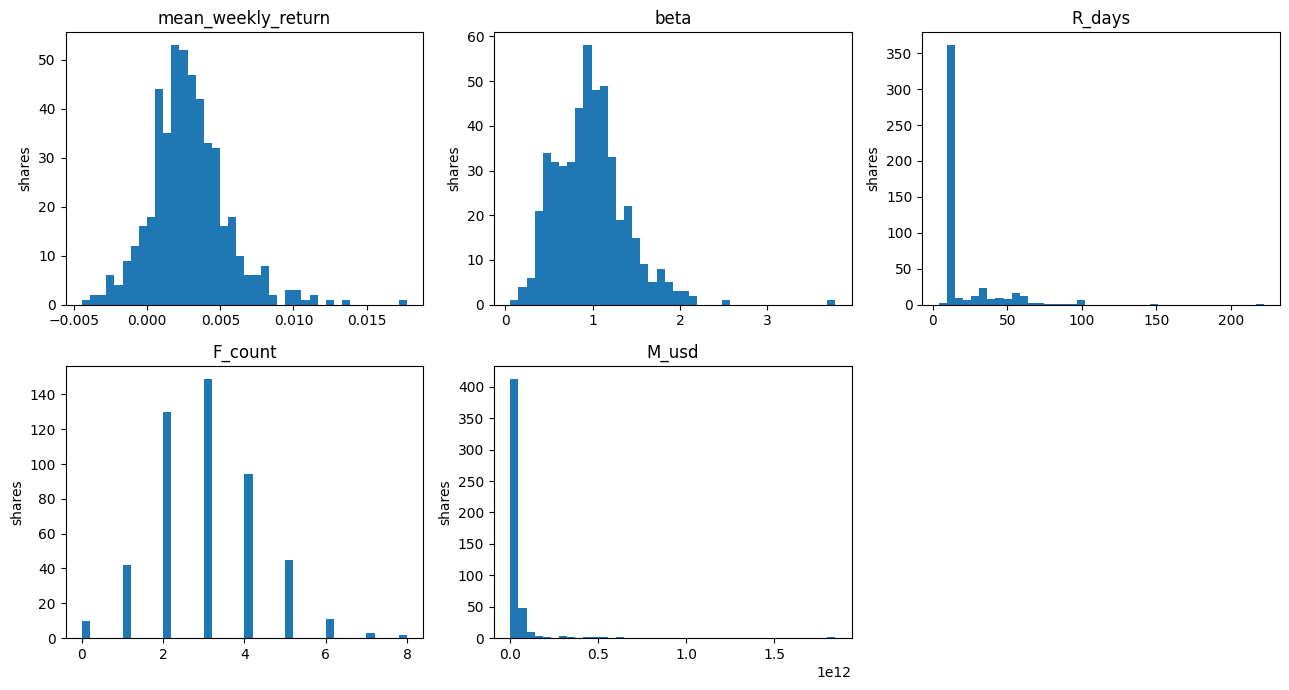

715

In [20]:
cols = ['mean_weekly_return', 'beta', 'R_days', 'F_count', 'M_usd']
print(feat[cols].describe().round(4).T)
print('\nskewness:'); print(feat[cols].skew().round(2))
print('\nshares per sector:'); print(feat['sector'].value_counts())

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(feat[c].dropna(), bins=40); ax.set_title(c); ax.set_ylabel('shares')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'task1_feature_distributions.png', dpi=150); plt.show()

meta.update({'observation_date': str(obs_date.date()), 'n_constituents_listed': len(cand),
             'n_retained': len(retained), 'n_excluded': int(len(excl)), 'n_weekly_returns': int(len(rets)),
             'rfm': {'baseline_sessions': RFM_BASE, 'window_sessions': RFM_WIN, 'multiple': RFM_MULT}})
(OUT_DIR / 'run_metadata.json').write_text(json.dumps(meta, indent=2, default=str))

**What each metric captures, and its limits as an investment signal**
* **Recency (R):** calendar days since the last unusually high-volume day. It records *when* trading activity last spiked, not whether the news was good or bad. When the latest event is the same market-wide day for most shares, R separates shares much less than its range suggests.
* **Frequency (F):** the number of unusually high-volume days in 60 sessions — how often activity spikes, not how much was traded.
* **Monetary (M):** approximate traded value in USD (Close × Volume). It is a liquidity and size proxy, not market capitalisation, profit or investor inflow, and it ignores spreads and price impact.
* These measures describe *past trading activity*. RFM comes from customer analytics; a high F or M is not evidence of a good investment, and none of these features predict returns.

# Task 2 — Stock Segmentation and Sensitivity Analysis
## Setup for clustering and plotting

In [21]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import sklearn, scipy
from scipy.cluster import hierarchy
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency, spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

SEED = 42                                    # one seed for every stochastic step
PALETTE = ['#4C78A8', '#F58518', '#54A24B', '#E45756', '#B279A2', '#72B7B2', '#EECA3B', '#9D755D']
hierarchy.set_link_color_palette(PALETTE)
FIG_DIR = OUT_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'axes.labelsize': 10, 'font.size': 10})
def savefig(name): plt.savefig(FIG_DIR / name, dpi=200, bbox_inches='tight')
print({'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__, 'seed': SEED})

{'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'seed': 42}


## 2.1 Feature preparation
Two separate feature matrices on the **same set of shares**: risk and return (mean weekly return, weekly beta) and trading activity (R, F, M). Monetary is transformed with `log1p` because traded value spans several orders of magnitude; each matrix is then standardised (zero mean, unit variance) separately so that no feature dominates Euclidean distance through its units. The five features are **not** combined into one score.

In [22]:
cs = feat[feat['common_valid_set']].reset_index(drop=True).copy()   # common valid share set
cs['logM'] = np.log1p(cs['M_usd'])
print('common valid share set:', len(cs), 'of', len(feat), 'retained shares')

RR_COLS  = ['mean_weekly_return', 'beta']
ACT_COLS = ['R_days', 'F_count', 'logM']
X_rr_raw, X_act_raw = cs[RR_COLS].copy(), cs[ACT_COLS].copy()
assert X_rr_raw.notna().all().all() and X_act_raw.notna().all().all()

sc_rr, sc_act = StandardScaler(), StandardScaler()
X_rr  = pd.DataFrame(sc_rr.fit_transform(X_rr_raw),   columns=RR_COLS,  index=cs['ticker'])
X_act = pd.DataFrame(sc_act.fit_transform(X_act_raw), columns=ACT_COLS, index=cs['ticker'])
assert X_rr.index.equals(X_act.index)
print('standardised means ~ 0:', float(X_rr.mean().abs().max()), float(X_act.mean().abs().max()))
print('standardised std  = 1:', X_rr.std(ddof=0).round(3).tolist(), X_act.std(ddof=0).round(3).tolist())

X_rr.to_csv(OUT_DIR / 'matrix_risk_return_standardised.csv')
X_act.to_csv(OUT_DIR / 'matrix_activity_standardised.csv')
cs[['ticker'] + RR_COLS].to_csv(OUT_DIR / 'matrix_risk_return_raw.csv', index=False)
cs[['ticker'] + ACT_COLS + ['M_usd']].to_csv(OUT_DIR / 'matrix_activity_raw.csv', index=False)

common valid share set: 486 of 486 retained shares
standardised means ~ 0: 1.2061682242841206e-16 4.375101104448765e-15
standardised std  = 1: [1.0, 1.0] [1.0, 1.0, 1.0]


**Skew and outlier inspection.** Skewness before and after the transformation, outliers (|z| > 3) in the model inputs, and how the transformation changes distances.

                         skew of raw feature  skew of model input  \
mean_weekly_return                      0.87                 0.87   
beta                                    1.10                 1.10   
R_days                                  3.65                 3.65   
F_count                                 0.42                 0.42   
Monetary (USD -> log1p)                11.68                 1.08   

                         skew if log1p applied  
mean_weekly_return                         NaN  
beta                                       NaN  
R_days                                    1.58  
F_count                                  -0.93  
Monetary (USD -> log1p)                   1.08  

Outliers |z| > 3 in model inputs:
mean_weekly_return     6
beta                   2
R_days                11
F_count                5
logM                   7
  most extreme mean_weekly_return: SMCI (+5.6), NVDA (+4.1), VRT (+3.7)
  most extreme beta: CVNA (+6.9), XYZ (+3.8), COHR (+2.9)
 

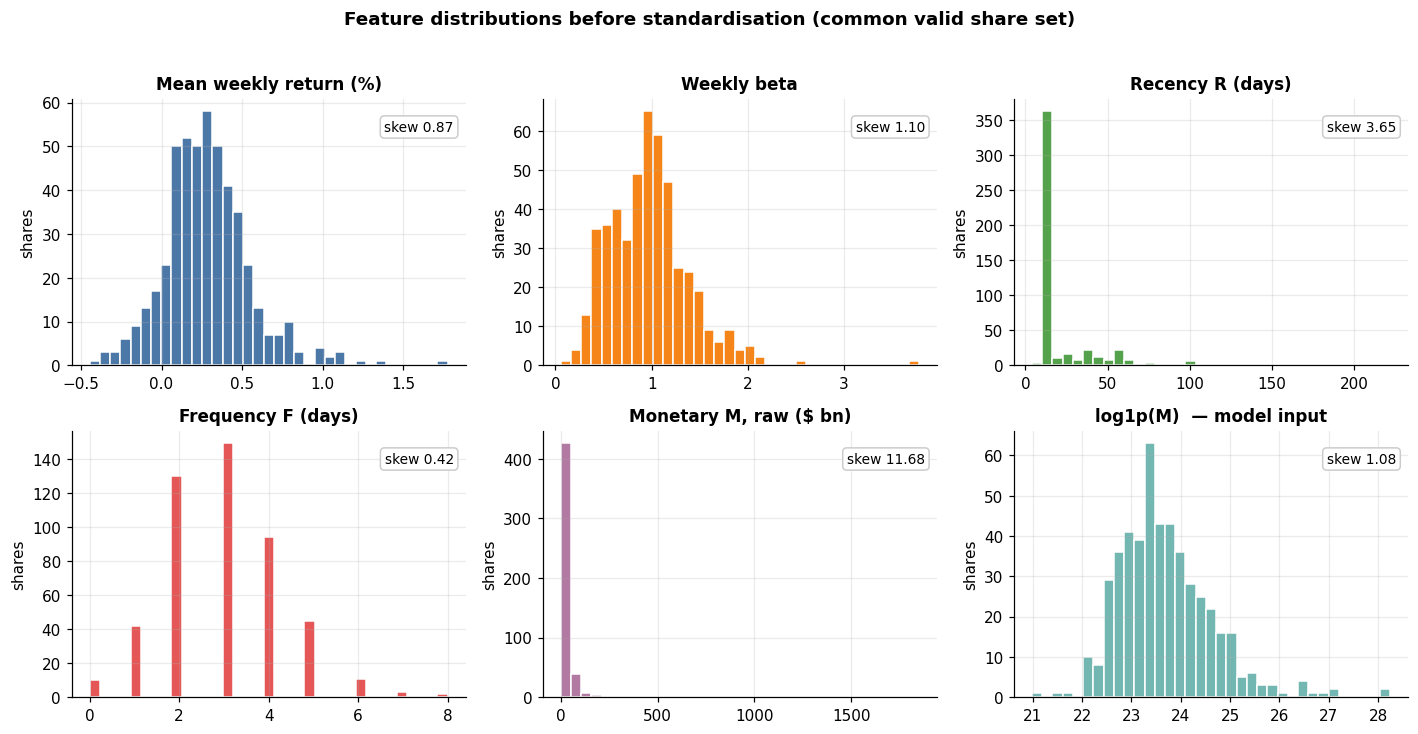

In [23]:
diag = pd.DataFrame({
    'skew of raw feature':   [cs['mean_weekly_return'].skew(), cs['beta'].skew(), cs['R_days'].skew(), cs['F_count'].skew(), cs['M_usd'].skew()],
    'skew of model input':   [cs['mean_weekly_return'].skew(), cs['beta'].skew(), cs['R_days'].skew(), cs['F_count'].skew(), cs['logM'].skew()],
    'skew if log1p applied': [np.nan, np.nan, np.log1p(cs['R_days']).skew(), np.log1p(cs['F_count']).skew(), cs['logM'].skew()],
}, index=['mean_weekly_return', 'beta', 'R_days', 'F_count', 'Monetary (USD -> log1p)']).round(2)
print(diag)

Z_all = pd.concat([X_rr, X_act], axis=1)
print('\nOutliers |z| > 3 in model inputs:'); print((Z_all.abs() > 3).sum().to_string())
for c in Z_all.columns:
    top = Z_all[c].abs().sort_values(ascending=False).head(3)
    print(f'  most extreme {c}:', ', '.join(f'{t} ({Z_all.loc[t, c]:+.1f})' for t in top.index))

# how much of the total squared distance do the 5 most extreme shares carry?
z_raw = (cs['M_usd'] - cs['M_usd'].mean()) / cs['M_usd'].std(ddof=0)
z_log = X_act['logM']
share5 = lambda z: (z**2).nlargest(5).sum() / (z**2).sum()
print(f"\nMonetary: top-5 shares carry {share5(z_raw):.0%} of squared deviation on the raw scale vs {share5(z_log):.0%} after log1p")

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
panels = [('mean_weekly_return', cs['mean_weekly_return'] * 100, 'Mean weekly return (%)'),
          ('beta', cs['beta'], 'Weekly beta'),
          ('R_days', cs['R_days'], 'Recency R (days)'),
          ('F_count', cs['F_count'], 'Frequency F (days)'),
          ('M_usd', cs['M_usd'] / 1e9, 'Monetary M, raw ($ bn)'),
          ('logM', cs['logM'], 'log1p(M)  — model input')]
for ax, (k, v, t), colr in zip(axes.ravel(), panels, PALETTE):
    ax.hist(v, bins=35, color=colr, edgecolor='white'); ax.set_title(t); ax.set_ylabel('shares')
    ax.text(0.97, 0.92, f'skew {pd.Series(v).skew():.2f}', transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(boxstyle='round', fc='white', ec='#cccccc'))
fig.suptitle('Feature distributions before standardisation (common valid share set)', fontweight='bold', y=1.02)
plt.tight_layout(); savefig('fig_2_1_feature_distributions.png'); plt.show()

**Treatment of other skewed variables.** Weekly beta and mean return are close to symmetric apart from a few extreme shares, so they are only standardised (a handful of outliers remain and pull on Euclidean distance; they are kept because they are real high-beta or high-return shares and are reported above). **F** is a bounded count with mild skew and is left in days. **R** is right-skewed and has many tied values because most shares share the same latest market-wide event day (see 1.4); `log1p(R)` would reduce skew but would also compress genuine differences between recent and old events, so R is kept in calendar days for interpretability and to match the Task 2.5 correlation specification. The skew table above documents what each choice would do.

## 2.2 Agglomerative clustering (Ward linkage, Euclidean distance)
**Suitability.** Ward's method merges the pair of clusters that gives the smallest increase in within-cluster variance, which suits compact, roughly spherical groups of standardised features. It is deterministic, shows the whole merge hierarchy in a dendrogram and needs no initial seeds. **Limitations.** It requires Euclidean distance (so scaling matters), it is sensitive to outliers (extreme shares form their own late-merging branches), merges are never undone, and it scales as O(n²), which is fine for about 500 shares.

**Choosing the number of clusters.** Cluster counts 2 to 8 are compared using silhouette scores, the smallest and largest cluster size, the gap between successive merge heights, and interpretable profiles. The dendrogram colour threshold is drawn **only to display** the chosen k — it does not define it. Default rule: among k ≥ 3 with no cluster smaller than 3% of shares, take the highest silhouette; set `K_OVERRIDE` to override after inspecting the evidence.

In [24]:
MIN_SIZE = max(5, int(round(0.03 * len(cs))))
K_RANGE = range(2, 9)
K_OVERRIDE = {}      # optional manual choice after inspecting the evidence, e.g. {'ward_act': 4}

def choose_k(tbl, key, kmin=3):
    if key in K_OVERRIDE: return K_OVERRIDE[key]
    ok = tbl[(tbl['k'] >= kmin) & (tbl['min_size'] >= MIN_SIZE)]
    if ok.empty: ok = tbl[tbl['k'] >= kmin]
    return int(ok.sort_values('silhouette', ascending=False).iloc[0]['k'])

def ward_run(X):
    Z = linkage(X.values, method='ward', metric='euclidean')
    coph = cophenet(Z, pdist(X.values))[0]
    rows, labs = [], {}
    for k in K_RANGE:
        lab = fcluster(Z, t=k, criterion='maxclust')
        sizes = np.bincount(lab)[1:]
        labs[k] = lab
        rows.append({'k': k, 'silhouette': round(silhouette_score(X.values, lab), 4), 'min_size': int(sizes.min()),
                     'max_size': int(sizes.max()), 'sizes': sorted(sizes.tolist(), reverse=True),
                     'merge_gap': round(float(Z[-(k - 1), 2] - Z[-k, 2]), 3)})
    return Z, coph, pd.DataFrame(rows), labs

ward = {}
for key, X, name in [('ward_rr', X_rr, 'risk-return'), ('ward_act', X_act, 'trading activity (R, F, M)')]:
    Z, coph, tbl, labs = ward_run(X)
    ward[key] = dict(Z=Z, coph=coph, tbl=tbl, labs=labs, k=choose_k(tbl, key), X=X, name=name)
    print(f"=== Ward | {name} | cophenetic correlation = {coph:.3f} | selected k = {ward[key]['k']}  (min cluster size rule: >= {MIN_SIZE})")
    display(tbl)

=== Ward | risk-return | cophenetic correlation = 0.479 | selected k = 5  (min cluster size rule: >= 15)


,k,silhouette,min_size,max_size,sizes,merge_gap
0,2,0.3395,92,394,"[394, 92]",4.271
1,3,0.2738,92,230,"[230, 164, 92]",4.592
2,4,0.2821,48,182,"[182, 164, 92, 48]",1.541
3,5,0.3041,48,182,"[182, 98, 92, 66, 48]",1.068
4,6,0.3204,5,182,"[182, 98, 87, 66, 48, 5]",3.260
5,7,0.3240,5,160,"[160, 98, 87, 66, 48, 22, 5]",0.033
6,8,0.3208,5,160,"[160, 98, 66, 56, 48, 31, 22, 5]",2.379


=== Ward | trading activity (R, F, M) | cophenetic correlation = 0.508 | selected k = 3  (min cluster size rule: >= 15)


,k,silhouette,min_size,max_size,sizes,merge_gap
0,2,0.3680,82,404,"[404, 82]",3.720
1,3,0.3040,82,250,"[250, 154, 82]",7.142
2,4,0.2888,43,207,"[207, 154, 82, 43]",0.691
3,5,0.3050,10,207,"[207, 154, 72, 43, 10]",1.572
4,6,0.3144,10,207,"[207, 136, 72, 43, 18, 10]",2.287
5,7,0.2917,10,141,"[141, 136, 72, 66, 43, 18, 10]",0.756
6,8,0.3021,10,141,"[141, 79, 72, 66, 57, 43, 18, 10]",0.568


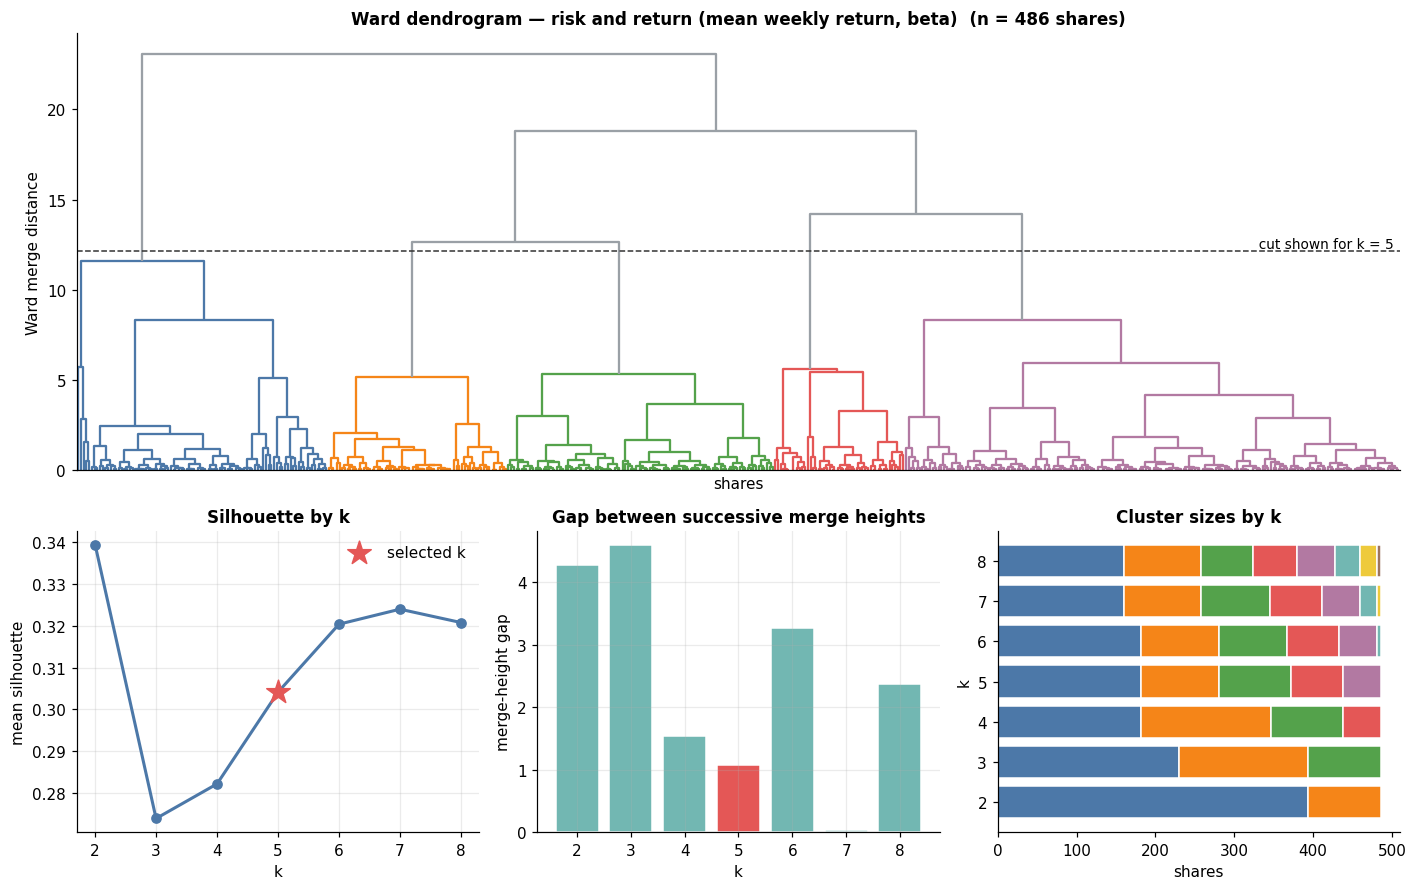

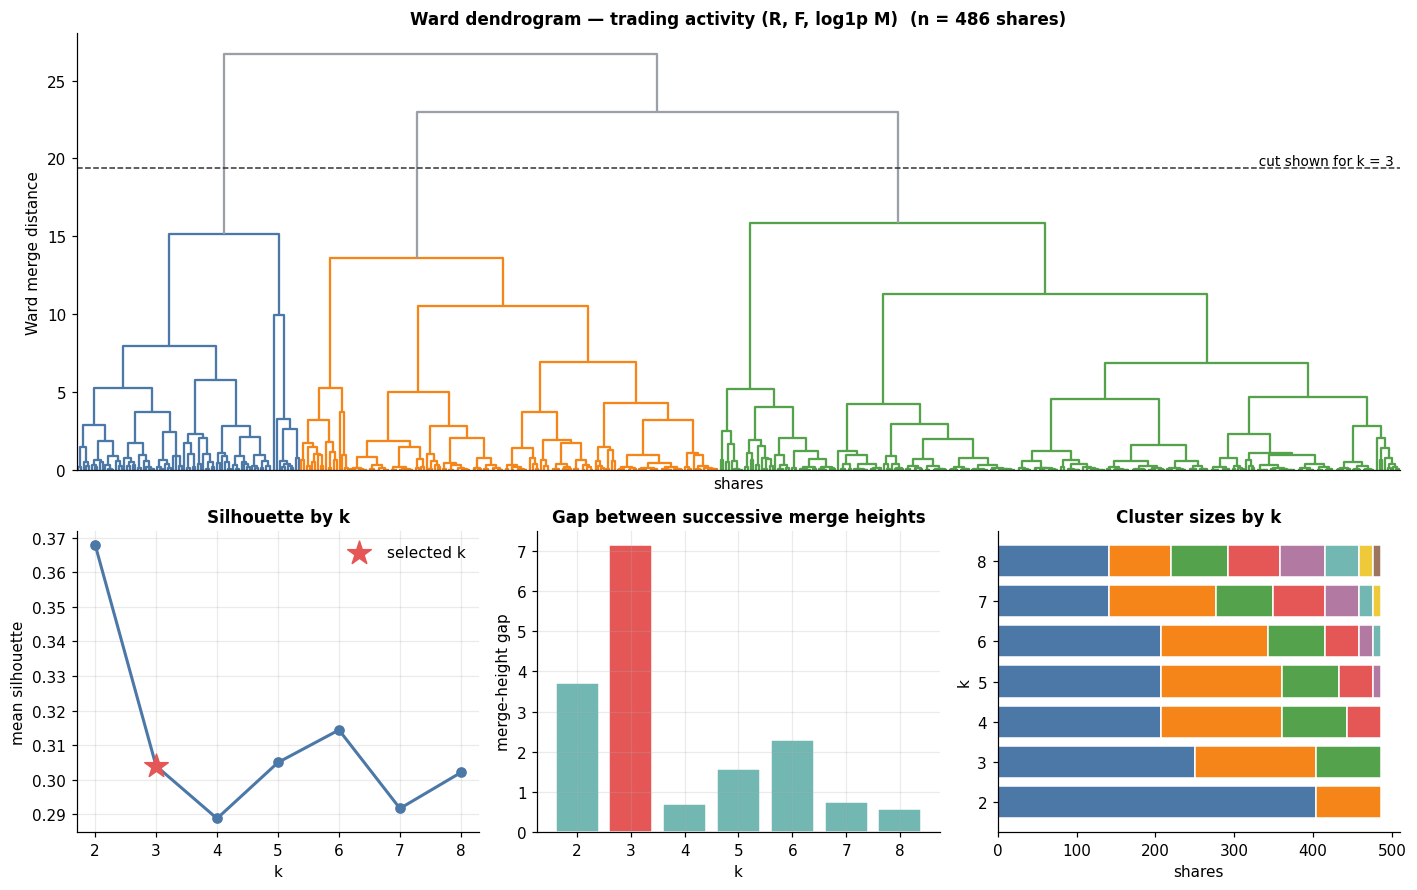

In [25]:
def plot_ward(key, title):
    d = ward[key]; Z, k, tbl = d['Z'], d['k'], d['tbl']
    thr = (Z[-(k - 1), 2] + Z[-k, 2]) / 2                 # drawn only to display the chosen k
    fig = plt.figure(figsize=(13, 8.2))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.45, 1])
    ax0 = fig.add_subplot(gs[0, :])
    dendrogram(Z, color_threshold=thr, above_threshold_color='#9AA0A6', no_labels=True, ax=ax0)
    ax0.axhline(thr, ls='--', color='#333333', lw=1)
    ax0.text(0.995, thr, f'  cut shown for k = {k}', transform=ax0.get_yaxis_transform(), ha='right', va='bottom', fontsize=9)
    ax0.set_title(f'Ward dendrogram — {title}  (n = {len(d["X"])} shares)'); ax0.set_ylabel('Ward merge distance'); ax0.set_xlabel('shares'); ax0.grid(False)
    ax1 = fig.add_subplot(gs[1, 0])
    ax1.plot(tbl['k'], tbl['silhouette'], marker='o', color=PALETTE[0], lw=2)
    ax1.scatter([k], [tbl.loc[tbl.k == k, 'silhouette'].iloc[0]], s=260, marker='*', color=PALETTE[3], zorder=5, label='selected k')
    ax1.set_title('Silhouette by k'); ax1.set_xlabel('k'); ax1.set_ylabel('mean silhouette'); ax1.legend(frameon=False)
    ax2 = fig.add_subplot(gs[1, 1])
    ax2.bar(tbl['k'], tbl['merge_gap'], color=[PALETTE[3] if kk == k else PALETTE[5] for kk in tbl['k']], edgecolor='white')
    ax2.set_title('Gap between successive merge heights'); ax2.set_xlabel('k'); ax2.set_ylabel('merge-height gap')
    ax3 = fig.add_subplot(gs[1, 2])
    for kk, sizes in zip(tbl['k'], tbl['sizes']):
        left = 0
        for j, s in enumerate(sizes):
            ax3.barh(kk, s, left=left, color=PALETTE[j % 8], edgecolor='white'); left += s
    ax3.set_yticks(list(tbl['k'])); ax3.set_title('Cluster sizes by k'); ax3.set_xlabel('shares'); ax3.set_ylabel('k'); ax3.grid(False)
    plt.tight_layout(); savefig(f'fig_2_2_{key}.png'); plt.show()

plot_ward('ward_rr',  'risk and return (mean weekly return, beta)')
plot_ward('ward_act', 'trading activity (R, F, log1p M)')

## 2.3 K-means clustering
**Suitability.** K-means partitions standardised features into k compact groups by minimising within-cluster squared distance (inertia); it is fast and gives interpretable centroids. **Limitations.** It assumes roughly spherical clusters of similar size, k must be fixed in advance, it is pulled by outliers, and the result depends on the starting centroids. A **fixed random seed** (`random_state = 42`) and **50 initialisations** (`n_init = 50`, best inertia kept) are used, and initialisation sensitivity is measured below. Counts 2 to 8 are compared using silhouette, inertia and cluster sizes.

In [26]:
def kmeans_run(X):
    rows, labs = [], {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, init='k-means++', n_init=50, random_state=SEED).fit(X.values)
        sizes = np.bincount(km.labels_)
        labs[k] = km.labels_ + 1
        rows.append({'k': k, 'inertia': round(km.inertia_, 2), 'silhouette': round(silhouette_score(X.values, km.labels_), 4),
                     'min_size': int(sizes.min()), 'max_size': int(sizes.max()), 'sizes': sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows), labs

def init_check(X, k, n_runs=30):
    ref = KMeans(n_clusters=k, init='k-means++', n_init=50, random_state=SEED).fit(X.values)
    inert, aris = [], []
    for s in range(n_runs):                                   # single random start, different seeds
        km1 = KMeans(n_clusters=k, init='random', n_init=1, random_state=s).fit(X.values)
        inert.append(km1.inertia_); aris.append(adjusted_rand_score(ref.labels_, km1.labels_))
    return ref.inertia_, np.array(inert), np.array(aris)

kmeans = {}
for key, X, name in [('km_rr', X_rr, 'risk-return'), ('km_act', X_act, 'trading activity (R, F, M)')]:
    tbl, labs = kmeans_run(X)
    k_sel = choose_k(tbl, key)
    best, inert, aris = init_check(X, k_sel)
    kmeans[key] = dict(tbl=tbl, labs=labs, k=k_sel, X=X, name=name, best=best, inert=inert, aris=aris)
    print(f"=== K-means | {name} | selected k = {k_sel}")
    display(tbl)
    reach = np.mean(np.isclose(inert, best, rtol=1e-6))
    print(f'    initialisation check at k = {k_sel}: best-of-50 inertia = {best:.2f}; 30 single random starts -> '
          f'median {np.median(inert):.2f}, worst {inert.max():.2f}; {reach:.0%} of single starts reach the best solution; '
          f'mean ARI vs best = {aris.mean():.3f}')

=== K-means | risk-return | selected k = 5


,k,inertia,silhouette,min_size,max_size,sizes
0,2,621.63,0.3870,143,343,"[343, 143]"
1,3,461.18,0.3289,119,202,"[202, 165, 119]"
2,4,371.58,0.3270,40,160,"[160, 154, 132, 40]"
3,5,309.61,0.3406,27,166,"[166, 131, 112, 50, 27]"
4,6,265.10,0.3349,5,156,"[156, 127, 105, 50, 43, 5]"
5,7,227.18,0.3285,5,128,"[128, 103, 85, 77, 47, 41, 5]"
6,8,194.36,0.3542,5,136,"[136, 79, 78, 76, 43, 40, 29, 5]"


    initialisation check at k = 5: best-of-50 inertia = 309.61; 30 single random starts -> median 313.53, worst 333.07; 0% of single starts reach the best solution; mean ARI vs best = 0.670
=== K-means | trading activity (R, F, M) | selected k = 4


,k,inertia,silhouette,min_size,max_size,sizes
0,2,1066.83,0.4231,68,418,"[418, 68]"
1,3,796.61,0.3250,64,270,"[270, 152, 64]"
2,4,609.83,0.3409,61,212,"[212, 122, 91, 61]"
3,5,514.71,0.3578,11,198,"[198, 122, 87, 68, 11]"
4,6,437.39,0.3467,11,143,"[143, 120, 105, 67, 40, 11]"
5,7,386.29,0.3474,1,141,"[141, 120, 104, 68, 41, 11, 1]"
6,8,342.17,0.3503,1,140,"[140, 106, 83, 66, 64, 15, 11, 1]"


    initialisation check at k = 4: best-of-50 inertia = 609.83; 30 single random starts -> median 609.94, worst 715.26; 3% of single starts reach the best solution; mean ARI vs best = 0.790


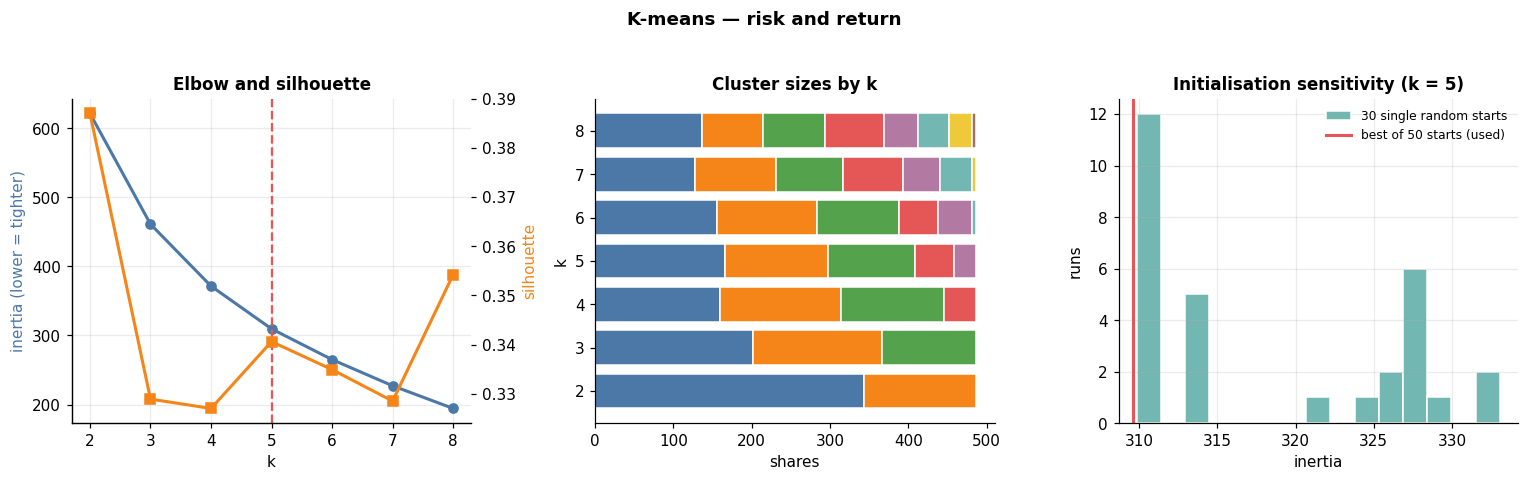

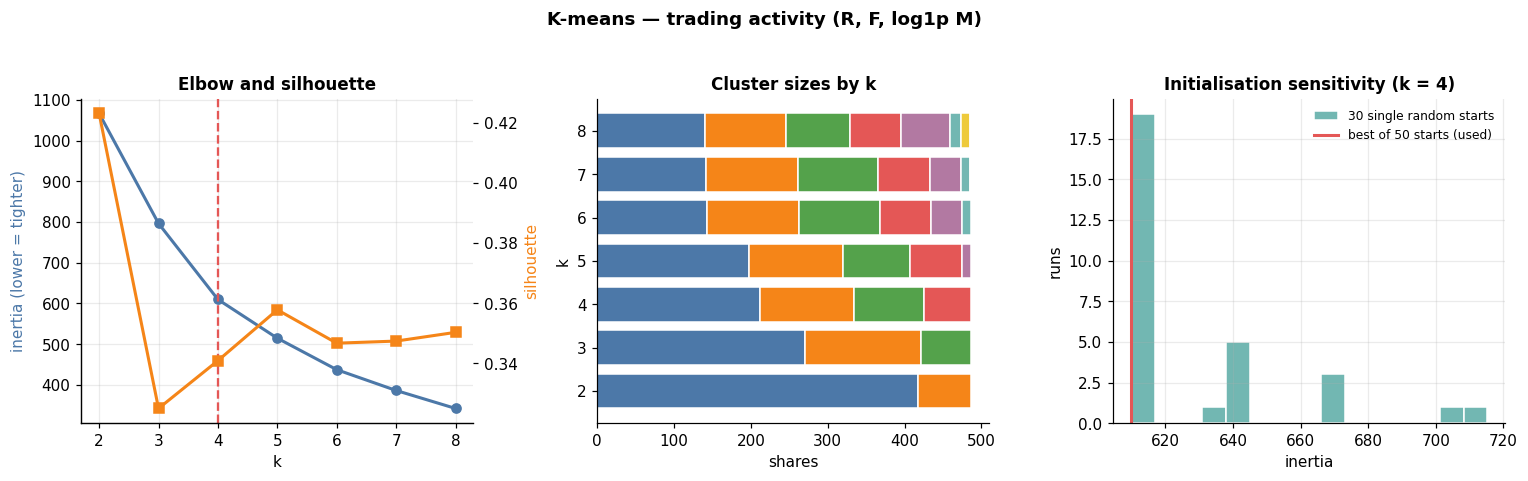

In [27]:
def plot_kmeans(key, title):
    d = kmeans[key]; tbl, k = d['tbl'], d['k']
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    ax = axes[0]; ax2 = ax.twinx()
    ax.plot(tbl['k'], tbl['inertia'], marker='o', color=PALETTE[0], lw=2); ax.set_ylabel('inertia (lower = tighter)', color=PALETTE[0])
    ax2.plot(tbl['k'], tbl['silhouette'], marker='s', color=PALETTE[1], lw=2); ax2.set_ylabel('silhouette', color=PALETTE[1]); ax2.grid(False)
    ax.axvline(k, ls='--', color=PALETTE[3]); ax.set_xlabel('k'); ax.set_title('Elbow and silhouette')
    ax = axes[1]
    for kk, sizes in zip(tbl['k'], tbl['sizes']):
        left = 0
        for j, s in enumerate(sizes):
            ax.barh(kk, s, left=left, color=PALETTE[j % 8], edgecolor='white'); left += s
    ax.set_yticks(list(tbl['k'])); ax.set_title('Cluster sizes by k'); ax.set_xlabel('shares'); ax.set_ylabel('k'); ax.grid(False)
    ax = axes[2]
    ax.hist(d['inert'], bins=15, color=PALETTE[5], edgecolor='white', label='30 single random starts')
    ax.axvline(d['best'], color=PALETTE[3], lw=2, label='best of 50 starts (used)')
    ax.set_title(f'Initialisation sensitivity (k = {k})'); ax.set_xlabel('inertia'); ax.set_ylabel('runs'); ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f'K-means — {title}', fontweight='bold', y=1.03)
    plt.tight_layout(); savefig(f'fig_2_3_{key}.png'); plt.show()

plot_kmeans('km_rr',  'risk and return')
plot_kmeans('km_act', 'trading activity (R, F, log1p M)')

## 2.4 Cluster profiles and algorithm comparison
The four baseline solutions (Ward and K-means on each matrix) use the chosen k for each. Clusters are numbered by size (1 = largest) and, where Ward and K-means use the same k on the same matrix, K-means labels are matched to the Ward labels (Hungarian assignment) so that colours are comparable. Cluster numbers are arbitrary, which is why agreement is measured with the adjusted Rand index. Profiles are in **original units**.

In [28]:
def rank_by_size(lab):
    lab = np.asarray(lab); order = pd.Series(lab).value_counts().index
    m = {old: new for new, old in enumerate(order, 1)}
    return np.array([m[x] for x in lab])

def align_to(ref, lab):
    ct = pd.crosstab(lab, ref); r, c = linear_sum_assignment(-ct.values)
    m = {ct.index[i]: ct.columns[j] for i, j in zip(r, c)}
    return np.array([m[x] for x in lab])

cs['ward_rr']  = rank_by_size(ward['ward_rr']['labs'][ward['ward_rr']['k']])
cs['ward_act'] = rank_by_size(ward['ward_act']['labs'][ward['ward_act']['k']])
cs['km_rr']    = rank_by_size(kmeans['km_rr']['labs'][kmeans['km_rr']['k']])
cs['km_act']   = rank_by_size(kmeans['km_act']['labs'][kmeans['km_act']['k']])
for w, m_ in [('ward_rr', 'km_rr'), ('ward_act', 'km_act')]:
    if cs[w].nunique() == cs[m_].nunique():
        cs[m_] = align_to(cs[w].values, cs[m_].values)

SOL = {'ward_rr': 'Ward | risk-return', 'km_rr': 'K-means | risk-return',
       'ward_act': 'Ward | activity (R, F, M)', 'km_act': 'K-means | activity (R, F, M)'}

def profile_table(col):
    g = cs.groupby(col)
    return pd.DataFrame({'shares': g.size(), 'mean_weekly_return_%': g['mean_weekly_return'].mean() * 100,
                         'beta_mean': g['beta'].mean(), 'R_days_median': g['R_days'].median(),
                         'F_count_mean': g['F_count'].mean(), 'traded_value_median_$bn': g['M_usd'].median() / 1e9}).round(3)
for col, name in SOL.items():
    print(f'--- {name} (original units; R and traded value as medians, others as means)')
    display(profile_table(col))

--- Ward | risk-return (original units; R and traded value as medians, others as means)


,shares,mean_weekly_return_%,beta_mean,R_days_median,F_count_mean,traded_value_median_$bn
ward_rr,,,,,,
1,182,0.132,0.973,11.0,3.011,12.985
2,98,0.422,0.710,11.0,2.704,17.649
3,92,0.632,1.298,11.0,3.196,24.184
4,66,0.088,0.439,11.0,2.894,17.701
5,48,0.200,1.628,11.0,3.229,28.698


--- K-means | risk-return (original units; R and traded value as medians, others as means)


,shares,mean_weekly_return_%,beta_mean,R_days_median,F_count_mean,traded_value_median_$bn
km_rr,,,,,,
1,112,0.034,1.020,11.0,3.018,13.503
2,166,0.427,0.996,11.0,2.892,17.720
3,27,0.928,1.559,11.0,3.222,28.211
4,131,0.206,0.533,11.0,2.977,15.044
5,50,0.241,1.632,11.0,3.160,32.148


--- Ward | activity (R, F, M) (original units; R and traded value as medians, others as means)


,shares,mean_weekly_return_%,beta_mean,R_days_median,F_count_mean,traded_value_median_$bn
ward_act,,,,,,
1,250,0.253,0.940,11.0,3.360,11.178
2,154,0.338,1.010,11.0,2.864,39.695
3,82,0.286,1.009,54.5,2.098,17.849


--- K-means | activity (R, F, M) (original units; R and traded value as medians, others as means)


,shares,mean_weekly_return_%,beta_mean,R_days_median,F_count_mean,traded_value_median_$bn
km_act,,,,,,
1,212,0.275,0.939,11.0,2.368,13.336
2,122,0.257,0.966,11.0,4.549,12.826
3,91,0.341,1.064,11.0,3.231,60.183
4,61,0.300,0.975,55.0,1.672,21.242


PCA on the standardised activity matrix: PC1 = 45.8%, PC2 = 33.6% of variance (total 79.4%)
           PC1    PC2
R_days   0.711  0.023
F_count -0.650  0.402
logM     0.268  0.915


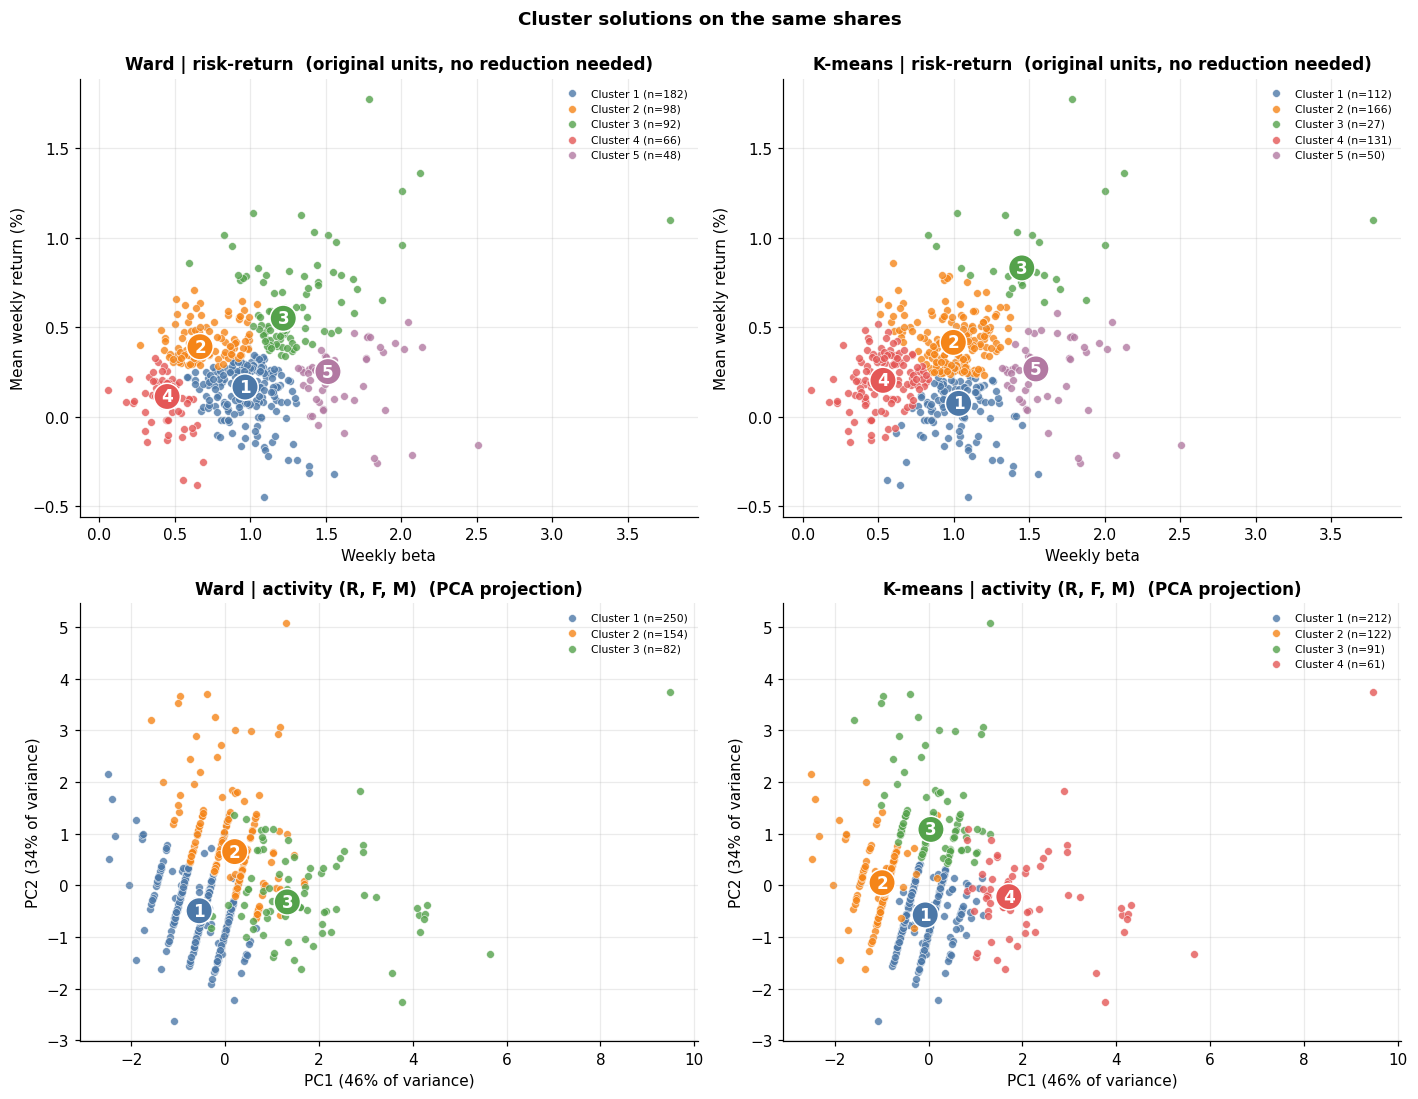

In [29]:
pca_act = PCA(n_components=2, random_state=SEED).fit(X_act.values)
P_act = pca_act.transform(X_act.values)
ev = pca_act.explained_variance_ratio_
print('PCA on the standardised activity matrix: PC1 = %.1f%%, PC2 = %.1f%% of variance (total %.1f%%)' % (ev[0]*100, ev[1]*100, ev.sum()*100))
print(pd.DataFrame(pca_act.components_.T, index=ACT_COLS, columns=['PC1', 'PC2']).round(3))

def scatter_clusters(ax, x, y, lab, title, xl, yl):
    for c in sorted(np.unique(lab)):
        m = lab == c; col = PALETTE[(c - 1) % 8]
        ax.scatter(x[m], y[m], s=26, alpha=.8, color=col, edgecolor='white', linewidth=.4, label=f'Cluster {c} (n={m.sum()})')
        ax.annotate(str(c), (np.median(x[m]), np.median(y[m])), ha='center', va='center', fontsize=11, fontweight='bold',
                    color='white', bbox=dict(boxstyle='circle,pad=0.25', fc=col, ec='white'))
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=7, frameon=False, loc='best')

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
bx, by = cs['beta'].values, cs['mean_weekly_return'].values * 100
for ax, col in zip(axes[0], ['ward_rr', 'km_rr']):
    scatter_clusters(ax, bx, by, cs[col].values, SOL[col] + '  (original units, no reduction needed)', 'Weekly beta', 'Mean weekly return (%)')
for ax, col in zip(axes[1], ['ward_act', 'km_act']):
    scatter_clusters(ax, P_act[:, 0], P_act[:, 1], cs[col].values, SOL[col] + '  (PCA projection)',
                     f'PC1 ({ev[0]*100:.0f}% of variance)', f'PC2 ({ev[1]*100:.0f}% of variance)')
fig.suptitle('Cluster solutions on the same shares', fontweight='bold', y=0.995)
plt.tight_layout(); savefig('fig_2_4_cluster_scatter.png'); plt.show()

**Visualisation note.** The risk-return matrix has two features, so it is plotted directly in original units with no dimensionality reduction. The activity matrix has three, so it is projected to two principal components of the standardised features; the projection keeps only the variance shown on the axes, so overlap in the plot does not mean the clusters overlap in the full space.

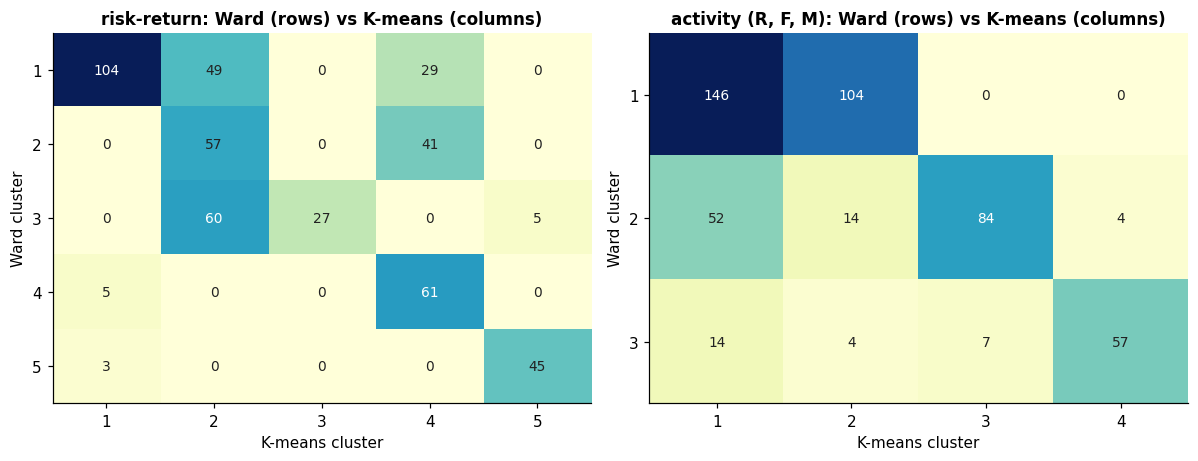

,matrix,k Ward,k K-means,ARI (Ward vs K-means),NMI,silhouette Ward,silhouette K-means
0,risk-return,5,5,0.318,0.503,0.304,0.341
1,"activity (R, F, M)",3,4,0.318,0.402,0.304,0.341


In [30]:
def heat(ax, ct, title, xl, yl, fmt='d', cmap='YlGnBu', rot=0):
    vals = ct.values.astype(float)
    ax.imshow(vals, cmap=cmap, aspect='auto')
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=rot, ha='right' if rot else 'center')
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    thr = vals.max() * 0.55
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            txt = format(int(round(vals[i, j])), 'd') if fmt == 'd' else format(vals[i, j], fmt)
            ax.text(j, i, txt, ha='center', va='center', fontsize=9, color='white' if vals[i, j] > thr else '#222222')
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(False)

rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (w, m_, nm) in zip(axes, [('ward_rr', 'km_rr', 'risk-return'), ('ward_act', 'km_act', 'activity (R, F, M)')]):
    ari = adjusted_rand_score(cs[w], cs[m_]); nmi = normalized_mutual_info_score(cs[w], cs[m_])
    X = ward[w]['X']
    rows.append({'matrix': nm, 'k Ward': cs[w].nunique(), 'k K-means': cs[m_].nunique(), 'ARI (Ward vs K-means)': round(ari, 3),
                 'NMI': round(nmi, 3), 'silhouette Ward': round(silhouette_score(X.values, cs[w]), 3),
                 'silhouette K-means': round(silhouette_score(X.values, cs[m_]), 3)})
    heat(ax, pd.crosstab(cs[w], cs[m_]), f'{nm}: Ward (rows) vs K-means (columns)', 'K-means cluster', 'Ward cluster')
plt.tight_layout(); savefig('fig_2_4_algorithm_agreement.png'); plt.show()
display(pd.DataFrame(rows))

## 2.5 RFM sensitivity and correlated inputs
### 2.5.1 Correlation analysis
R, F and log1p(M) are correlated. Euclidean distance adds the squared differences of the standardised features, so two correlated features measure largely the same underlying dimension and that dimension is counted twice; standardisation equalises each feature's *variance* but not the amount of shared information. A high correlation shows overlap, **not** proof that one feature dominates the clustering — that is tested by removing Monetary in 2.5.2.

Pearson correlations:
         R_days  F_count   logM
R_days    1.000   -0.346  0.152
F_count  -0.346    1.000  0.013
logM      0.152    0.013  1.000

Spearman correlations:
         R_days  F_count   logM
R_days    1.000   -0.196  0.137
F_count  -0.196    1.000 -0.048
logM      0.137   -0.048  1.000

Variance inflation factors: {'R_days': 1.17, 'F_count': 1.14, 'logM': 1.03}
PCA variance ratio of standardised (R, F, log1p M): [45.8, 33.6, 20.6]
           PC1    PC2    PC3
R_days   0.711  0.023  0.703
F_count -0.650  0.402  0.645
logM     0.268  0.915 -0.301


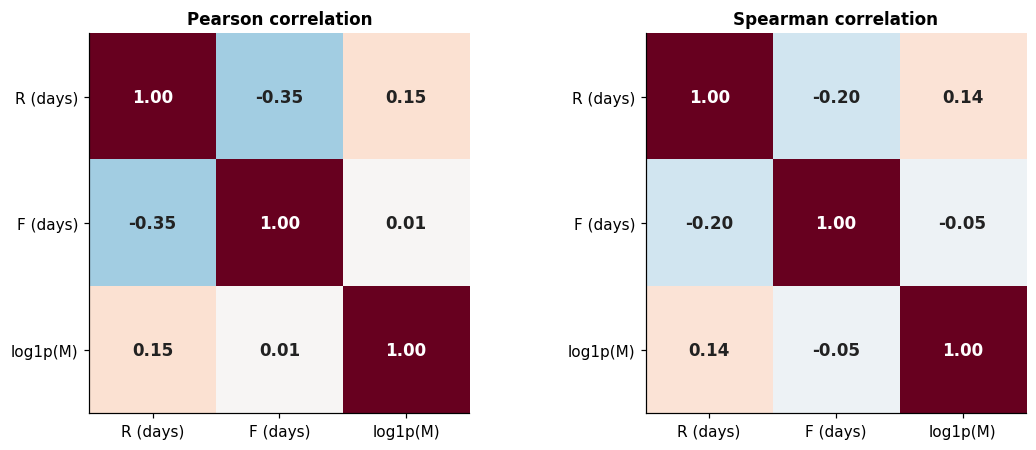

In [31]:
rfm_cols = ['R_days', 'F_count', 'logM']
corr_p = cs[rfm_cols].corr(); corr_s = cs[rfm_cols].corr(method='spearman')
print('Pearson correlations:'); print(corr_p.round(3)); print('\nSpearman correlations:'); print(corr_s.round(3))
vif = pd.Series(np.diag(np.linalg.inv(corr_p.values)), index=rfm_cols)
print('\nVariance inflation factors:', vif.round(2).to_dict())
pca3 = PCA(random_state=SEED).fit(X_act.values)
print('PCA variance ratio of standardised (R, F, log1p M):', (pca3.explained_variance_ratio_ * 100).round(1).tolist())
print(pd.DataFrame(pca3.components_.T, index=ACT_COLS, columns=['PC1', 'PC2', 'PC3']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, cm, t in zip(axes, [corr_p, corr_s], ['Pearson', 'Spearman']):
    ax.imshow(cm.values, cmap='RdBu_r', vmin=-1, vmax=1)
    labs_ = ['R (days)', 'F (days)', 'log1p(M)']
    ax.set_xticks(range(3)); ax.set_xticklabels(labs_); ax.set_yticks(range(3)); ax.set_yticklabels(labs_)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cm.values[i, j]:.2f}', ha='center', va='center', fontsize=11, fontweight='bold',
                    color='white' if abs(cm.values[i, j]) > 0.55 else '#222222')
    ax.set_title(f'{t} correlation'); ax.grid(False)
plt.tight_layout(); savefig('fig_2_5_1_correlations.png'); plt.show()

### 2.5.2 Removal of Monetary
The selected Ward activity solution is repeated using **R and F only**: same shares, same number of clusters, scaler refitted on the two remaining features. Memberships are compared with the **adjusted Rand index** (unaffected by arbitrary cluster numbering). Traded-value profiles show whether Monetary mainly separates *activity* or *liquidity* levels. Traded value is only a liquidity proxy: spread and price impact are not measured here.

k = 3 | adjusted Rand index, full RFM vs R-and-F only: 0.291 | silhouette (R,F space): 0.488


,full RFM: shares,full RFM: median traded value $bn,"R,F only: shares","R,F only: median traded value $bn"
1,250,11.18,272,14.86
2,154,39.70,125,17.70
3,82,17.85,89,20.85


share of between-cluster variance in log10 traded value (eta squared):
   full RFM clusters: 0.52   |   R,F-only clusters: 0.00
Spearman rho of Monetary with F: -0.05 | with R: +0.14


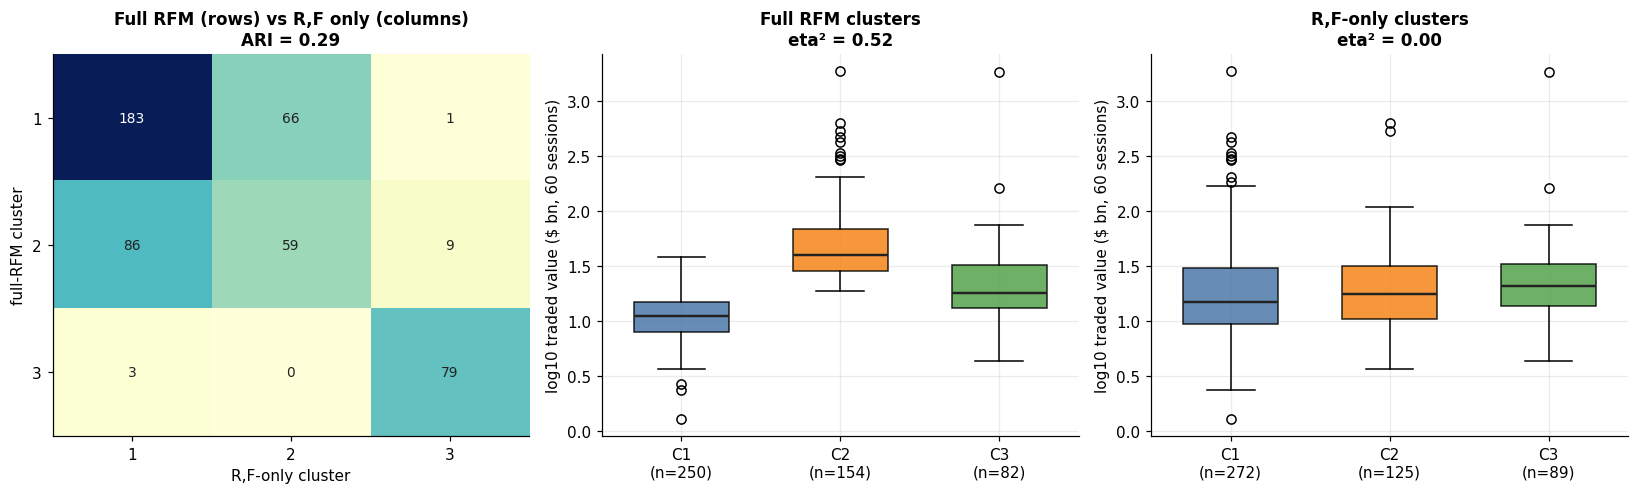

In [32]:
def eta_sq(values, labels):
    v = pd.Series(np.asarray(values, dtype=float)); g = v.groupby(np.asarray(labels))
    return float((g.size() * (g.mean() - v.mean()) ** 2).sum() / ((v - v.mean()) ** 2).sum())

k_full = int(cs['ward_act'].nunique())
X_rf = StandardScaler().fit_transform(cs[['R_days', 'F_count']].values)        # fresh standardisation
Z_rf = linkage(X_rf, method='ward', metric='euclidean')
lab_rf = fcluster(Z_rf, t=k_full, criterion='maxclust')
cs['ward_rf'] = rank_by_size(lab_rf)
if cs['ward_rf'].nunique() != k_full:
    print(f"WARNING: R-and-F-only Ward returned {cs['ward_rf'].nunique()} clusters instead of {k_full} (tied distances); see the report.")
cs['ward_rf'] = align_to(cs['ward_act'].values, cs['ward_rf'].values) if cs['ward_rf'].nunique() == k_full else cs['ward_rf']

ari_rf = adjusted_rand_score(cs['ward_act'], cs['ward_rf'])
print(f'k = {k_full} | adjusted Rand index, full RFM vs R-and-F only: {ari_rf:.3f} | silhouette (R,F space): {silhouette_score(X_rf, cs["ward_rf"]):.3f}')

logM_bn = np.log10(cs['M_usd'] / 1e9)
tv = pd.DataFrame({
    'full RFM: shares': cs.groupby('ward_act').size(),
    'full RFM: median traded value $bn': cs.groupby('ward_act')['M_usd'].median() / 1e9,
    'R,F only: shares': cs.groupby('ward_rf').size(),
    'R,F only: median traded value $bn': cs.groupby('ward_rf')['M_usd'].median() / 1e9}).round(2)
display(tv)
print('share of between-cluster variance in log10 traded value (eta squared):')
print(f"   full RFM clusters: {eta_sq(logM_bn, cs['ward_act']):.2f}   |   R,F-only clusters: {eta_sq(logM_bn, cs['ward_rf']):.2f}")
rho_F, rho_R = spearmanr(cs['M_usd'], cs['F_count'])[0], spearmanr(cs['M_usd'], cs['R_days'])[0]
print(f'Spearman rho of Monetary with F: {rho_F:+.2f} | with R: {rho_R:+.2f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
heat(axes[0], pd.crosstab(cs['ward_act'], cs['ward_rf']), f'Full RFM (rows) vs R,F only (columns)\nARI = {ari_rf:.2f}', 'R,F-only cluster', 'full-RFM cluster')
for ax, col, t in [(axes[1], 'ward_act', 'Full RFM clusters'), (axes[2], 'ward_rf', 'R,F-only clusters')]:
    cl = sorted(cs[col].unique())
    bp = ax.boxplot([logM_bn[cs[col] == c] for c in cl], patch_artist=True, widths=.6, medianprops=dict(color='#222222', lw=1.6))
    for patch, c in zip(bp['boxes'], cl): patch.set_facecolor(PALETTE[(c - 1) % 8]); patch.set_alpha(.85)
    ax.set_xticklabels([f'C{c}\n(n={int((cs[col] == c).sum())})' for c in cl]); ax.set_ylabel('log10 traded value ($ bn, 60 sessions)')
    ax.set_title(f'{t}\neta² = {eta_sq(logM_bn, cs[col]):.2f}')
plt.tight_layout(); savefig('fig_2_5_2_monetary_removal.png'); plt.show()

# Task 3 — Business Intelligence and Critical Review: supporting evidence
Figures and statistics for 3.2 (the written review is in the report; 3.1 data-mart design is also written).
## 3.2.1 Cluster profiles and sector composition

In [33]:
sector_order = cs['sector'].value_counts().index.tolist()
overall_sector = (cs['sector'].value_counts(normalize=True).reindex(sector_order) * 100).round(1)

def sector_mix(col):
    ct = pd.crosstab(cs[col], cs['sector'])[sector_order]
    return ct, (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

def cramers_v(ct):
    chi2, p, _, _ = chi2_contingency(ct.values); n = ct.values.sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1)))), float(p)

for col in ['ward_rr', 'ward_act']:
    ct, pct = sector_mix(col); v, p = cramers_v(ct)
    print(f'=== {SOL[col]}: sector composition (row %), Cramer V = {v:.2f}, chi-square p = {p:.3g}')
    display(pd.concat([pct, overall_sector.to_frame('ALL SHARES').T]))

ari_cross = adjusted_rand_score(cs['ward_rr'], cs['ward_act']); nmi_cross = normalized_mutual_info_score(cs['ward_rr'], cs['ward_act'])
print(f'\nAgreement between risk-return clusters and RFM clusters (Ward): ARI = {ari_cross:.3f}, NMI = {nmi_cross:.3f}')
print(f"Agreement between risk-return and RFM clusters (K-means):       ARI = {adjusted_rand_score(cs['km_rr'], cs['km_act']):.3f}")

=== Ward | risk-return: sector composition (row %), Cramer V = 0.43, chi-square p = 4.4e-52


sector,Industrials,Information Technology,Financials,Health Care,Consumer Discretionary,Consumer Staples,Utilities,Real Estate,Materials,Communication Services,Energy
1,22.0,11.0,14.3,13.7,9.3,2.7,2.7,12.6,7.7,3.8,0.0
2,11.2,2.0,28.6,8.2,9.2,5.1,8.2,3.1,3.1,5.1,16.3
3,22.8,31.5,14.1,2.2,12.0,0.0,1.1,3.3,3.3,5.4,4.3
4,3.0,0.0,3.0,28.8,0.0,33.3,24.2,1.5,1.5,4.5,0.0
5,8.3,47.9,10.4,8.3,20.8,0.0,0.0,0.0,4.2,0.0,0.0
ALL SHARES,16.0,15.2,15.2,11.9,9.7,6.6,6.2,6.2,4.7,4.1,4.1


=== Ward | activity (R, F, M): sector composition (row %), Cramer V = 0.26, chi-square p = 7.17e-07


sector,Industrials,Information Technology,Financials,Health Care,Consumer Discretionary,Consumer Staples,Utilities,Real Estate,Materials,Communication Services,Energy
1,20.4,10.0,15.6,11.2,7.2,5.6,8.0,10.8,5.2,2.8,3.2
2,13.6,20.1,16.2,13.6,13.0,7.1,0.6,1.9,1.3,5.8,6.5
3,7.3,22.0,12.2,11.0,11.0,8.5,11.0,0.0,9.8,4.9,2.4
ALL SHARES,16.0,15.2,15.2,11.9,9.7,6.6,6.2,6.2,4.7,4.1,4.1



Agreement between risk-return clusters and RFM clusters (Ward): ARI = 0.039, NMI = 0.022
Agreement between risk-return and RFM clusters (K-means):       ARI = 0.021


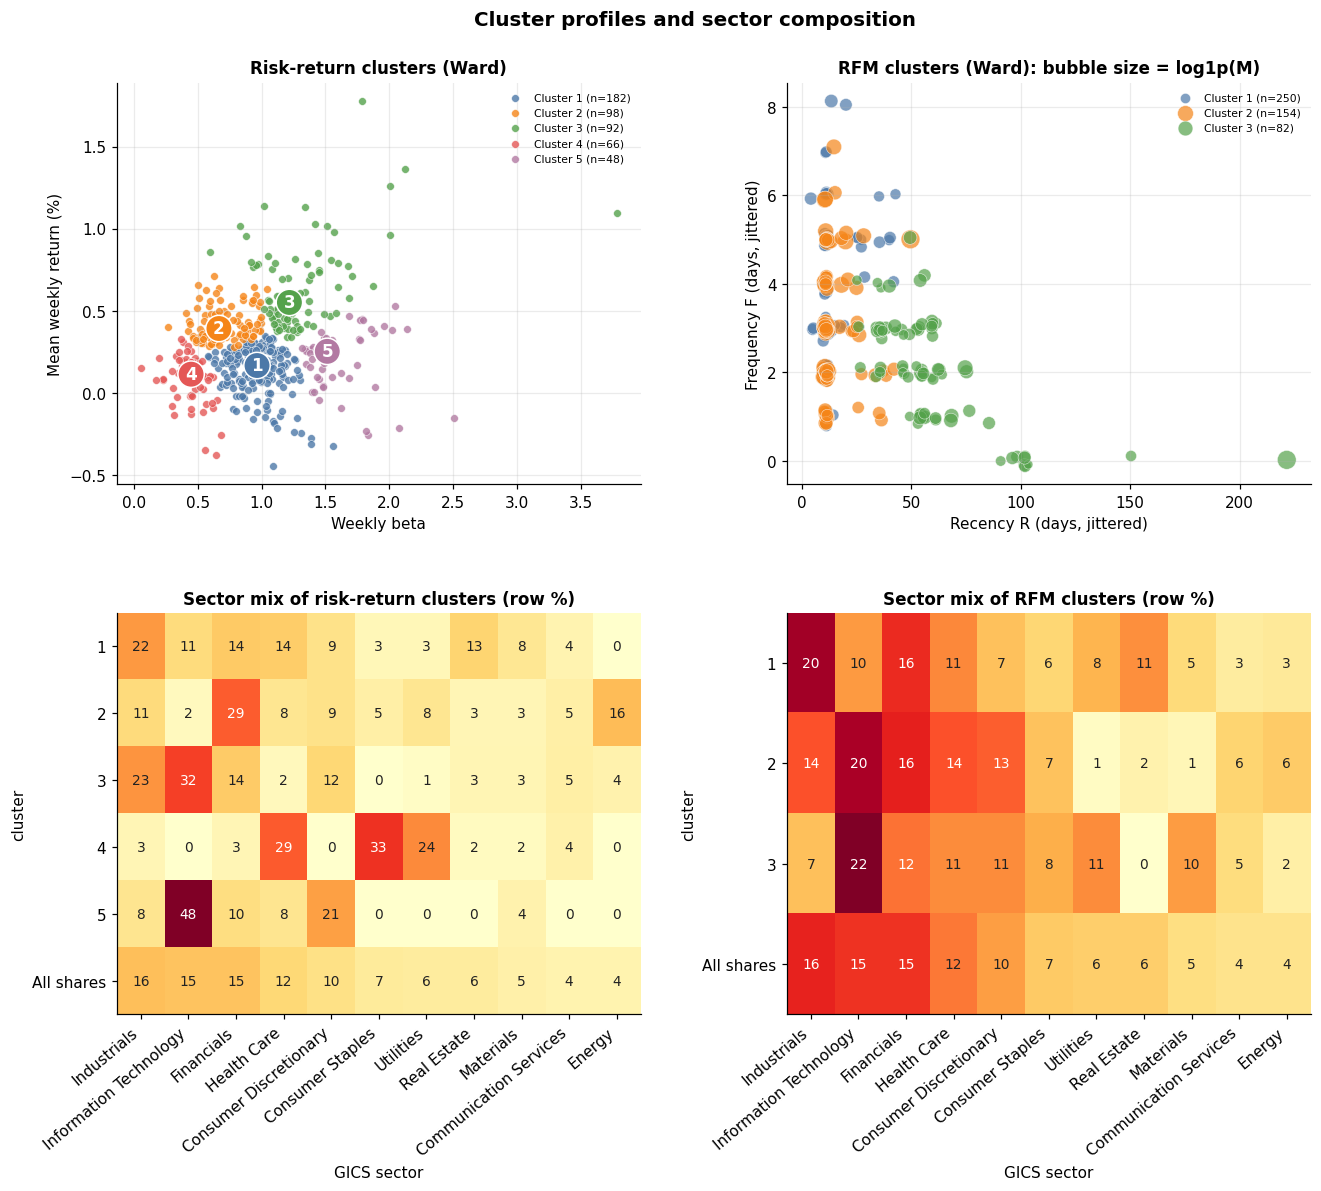

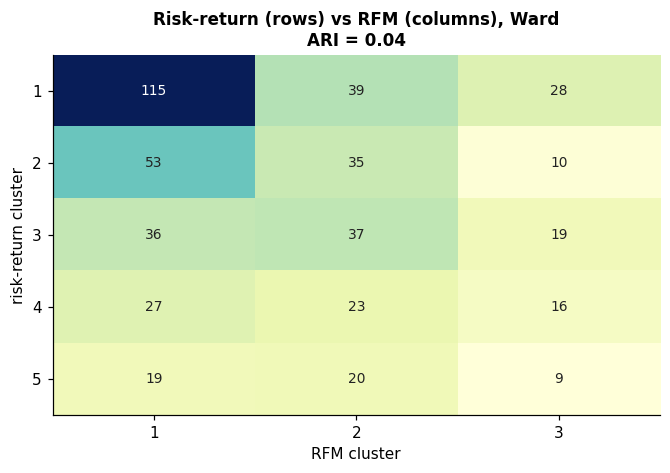

In [34]:
rng = np.random.default_rng(SEED)
fig = plt.figure(figsize=(14, 11))
gs = fig.add_gridspec(2, 2, hspace=0.32, wspace=0.28)
ax = fig.add_subplot(gs[0, 0])
scatter_clusters(ax, cs['beta'].values, cs['mean_weekly_return'].values * 100, cs['ward_rr'].values,
                 'Risk-return clusters (Ward)', 'Weekly beta', 'Mean weekly return (%)')
ax = fig.add_subplot(gs[0, 1])
jx = cs['R_days'].values + rng.normal(0, 0.6, len(cs)); jy = cs['F_count'].values + rng.normal(0, 0.08, len(cs))
sizes_ = 12 + 140 * (cs['logM'] - cs['logM'].min()) / (cs['logM'].max() - cs['logM'].min())
for c in sorted(cs['ward_act'].unique()):
    m = (cs['ward_act'] == c).values
    ax.scatter(jx[m], jy[m], s=sizes_[m], alpha=.7, color=PALETTE[(c - 1) % 8], edgecolor='white', linewidth=.4, label=f'Cluster {c} (n={m.sum()})')
ax.set_title('RFM clusters (Ward): bubble size = log1p(M)'); ax.set_xlabel('Recency R (days, jittered)'); ax.set_ylabel('Frequency F (days, jittered)')
ax.legend(fontsize=7, frameon=False)
for pos, col, t in [(gs[1, 0], 'ward_rr', 'Sector mix of risk-return clusters (row %)'), (gs[1, 1], 'ward_act', 'Sector mix of RFM clusters (row %)')]:
    ax = fig.add_subplot(pos); _, pct = sector_mix(col)
    pct2 = pd.concat([pct, overall_sector.to_frame('All shares').T])
    heat(ax, pct2, t, 'GICS sector', 'cluster', fmt='.0f', cmap='YlOrRd', rot=40)
fig.suptitle('Cluster profiles and sector composition', fontweight='bold', fontsize=13, y=0.94)
savefig('fig_3_2_1_overview.png'); plt.show()

fig, ax = plt.subplots(figsize=(6.2, 4.4))
heat(ax, pd.crosstab(cs['ward_rr'], cs['ward_act']), f'Risk-return (rows) vs RFM (columns), Ward\nARI = {ari_cross:.2f}', 'RFM cluster', 'risk-return cluster')
plt.tight_layout(); savefig('fig_3_2_1_rr_vs_rfm.png'); plt.show()

## 3.2.3 Evidence for critical evaluation: return dependence and estimate stability

Average pairwise weekly-return correlation: all shares 0.30
within risk-return clusters: {1: 0.37, 2: 0.32, 3: 0.37, 4: 0.31, 5: 0.44}
within RFM clusters:         {1: 0.33, 2: 0.28, 3: 0.27}

Persistence across the two halves of the period (103 and 104 weeks): beta correlation = 0.78, mean-return correlation = -0.30


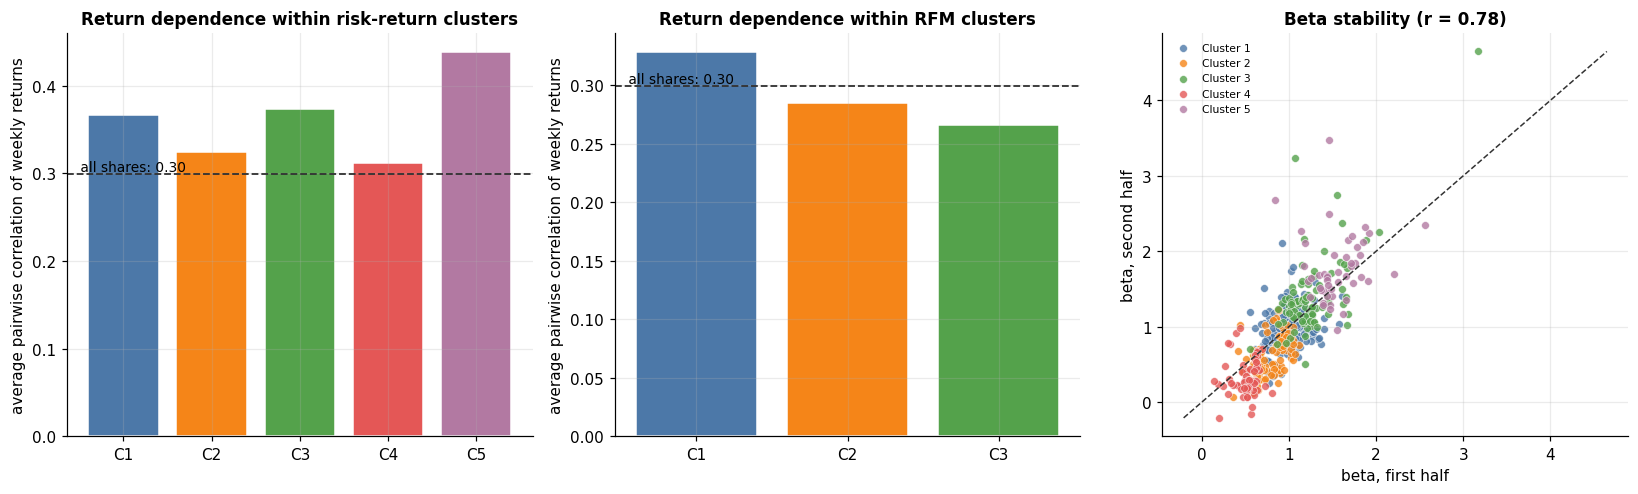

In [35]:
R_w = rets[cs['ticker']]
C = R_w.corr().values; n_ = len(C); off = ~np.eye(n_, dtype=bool)
overall_corr = float(C[off].mean())

def within_corr(lab):
    out = {}
    for c in sorted(np.unique(lab)):
        idx = np.where(lab == c)[0]
        out[c] = float(C[np.ix_(idx, idx)][~np.eye(len(idx), dtype=bool)].mean()) if len(idx) > 1 else np.nan
    return pd.Series(out)

wc_rr, wc_act = within_corr(cs['ward_rr'].values), within_corr(cs['ward_act'].values)
print(f'Average pairwise weekly-return correlation: all shares {overall_corr:.2f}')
print('within risk-return clusters:', wc_rr.round(2).to_dict())
print('within RFM clusters:        ', wc_act.round(2).to_dict())

half = len(rets) // 2
def beta_on(df): return df[cs['ticker']].apply(lambda s: s.cov(df[BENCH])) / df[BENCH].var()
b1, b2 = beta_on(rets.iloc[:half]), beta_on(rets.iloc[half:])
m1, m2 = rets.iloc[:half][cs['ticker']].mean(), rets.iloc[half:][cs['ticker']].mean()
r_beta, r_mean = np.corrcoef(b1, b2)[0, 1], np.corrcoef(m1, m2)[0, 1]
print(f'\nPersistence across the two halves of the period ({half} and {len(rets) - half} weeks): '
      f'beta correlation = {r_beta:.2f}, mean-return correlation = {r_mean:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, wc, nm in [(axes[0], wc_rr, 'risk-return clusters'), (axes[1], wc_act, 'RFM clusters')]:
    ax.bar([f'C{c}' for c in wc.index], wc.values, color=[PALETTE[(c - 1) % 8] for c in wc.index], edgecolor='white')
    ax.axhline(overall_corr, ls='--', color='#333333', lw=1.2); ax.text(0.02, overall_corr, f' all shares: {overall_corr:.2f}', transform=ax.get_yaxis_transform(), va='bottom', fontsize=9)
    ax.set_ylabel('average pairwise correlation of weekly returns'); ax.set_title(f'Return dependence within {nm}')
ax = axes[2]
for c in sorted(cs['ward_rr'].unique()):
    m = (cs['ward_rr'] == c).values
    ax.scatter(b1[m], b2[m], s=26, alpha=.8, color=PALETTE[(c - 1) % 8], edgecolor='white', linewidth=.4, label=f'Cluster {c}')
lim = [min(b1.min(), b2.min()), max(b1.max(), b2.max())]; ax.plot(lim, lim, ls='--', color='#333333', lw=1)
ax.set_xlabel('beta, first half'); ax.set_ylabel('beta, second half'); ax.set_title(f'Beta stability (r = {r_beta:.2f})'); ax.legend(fontsize=7, frameon=False)
plt.tight_layout(); savefig('fig_3_2_3_dependence_and_stability.png'); plt.show()

In [36]:
# 3.2.3 permutation baseline: is within-cluster correlation higher than chance?
def within_overall(lab):
    tot, pairs = 0.0, 0
    for c in np.unique(lab):
        idx = np.where(lab == c)[0]; k = len(idx)
        if k > 1:
            sub = C[np.ix_(idx, idx)]
            tot += sub[~np.eye(k, dtype=bool)].sum(); pairs += k * (k - 1)
    return tot / pairs

rng = np.random.default_rng(SEED)
rows = []
for name, col in [('Ward risk-return', 'ward_rr'), ('K-means risk-return', 'km_rr'),
                  ('Ward RFM', 'ward_act'), ('K-means RFM', 'km_act')]:
    lab = cs[col].values
    obs = within_overall(lab)
    null = np.array([within_overall(rng.permutation(lab)) for _ in range(1000)])
    lo, hi = np.percentile(null, [2.5, 97.5])
    rows.append((name, round(obs, 3), round(null.mean(), 3), f'{lo:.3f} to {hi:.3f}', round((np.sum(null >= obs) + 1) / 1001, 4)))
perm = pd.DataFrame(rows, columns=['solution', 'within-cluster corr', 'chance mean', 'chance 95% range', 'p-value'])
print(f'average correlation over all pairs: {overall_corr:.3f}')
perm

average correlation over all pairs: 0.300


,solution,within-cluster corr,chance mean,chance 95% range,p-value
0,Ward risk-return,0.359,0.299,0.294 to 0.305,0.001
1,K-means risk-return,0.350,0.300,0.295 to 0.304,0.001
2,Ward RFM,0.312,0.299,0.295 to 0.304,0.001
3,K-means RFM,0.314,0.300,0.295 to 0.305,0.001


## Save cluster assignments and run record

In [37]:
out = cs[['ticker', 'security', 'sector', 'mean_weekly_return', 'beta', 'R_days', 'F_count', 'M_usd',
          'ward_rr', 'km_rr', 'ward_act', 'km_act', 'ward_rf']].copy()
out.columns = ['ticker', 'security', 'sector', 'mean_weekly_return', 'beta', 'R_days', 'F_count', 'M_usd',
               'cluster_ward_risk_return', 'cluster_kmeans_risk_return', 'cluster_ward_activity',
               'cluster_kmeans_activity', 'cluster_ward_R_F_only']
out.to_csv(OUT_DIR / 'cluster_assignments.csv', index=False)
meta.update({'seed': SEED, 'selected_k': {'ward_risk_return': int(cs['ward_rr'].nunique()), 'kmeans_risk_return': int(cs['km_rr'].nunique()),
                                          'ward_activity': int(cs['ward_act'].nunique()), 'kmeans_activity': int(cs['km_act'].nunique())},
             'kmeans': {'n_init': 50, 'init': 'k-means++'}, 'min_cluster_size_rule': MIN_SIZE,
             'sklearn': sklearn.__version__, 'scipy': scipy.__version__})
import hashlib
meta['raw_prices_sha256'] = hashlib.sha256((DATA_DIR / 'raw_prices_long.csv.gz').read_bytes()).hexdigest()
(OUT_DIR / 'run_metadata.json').write_text(json.dumps(meta, indent=2, default=str))
print('saved:', sorted(p.name for p in OUT_DIR.iterdir() if p.is_file()))
print('figures:', sorted(p.name for p in FIG_DIR.iterdir()))

saved: ['cluster_assignments.csv', 'exclusion_log.csv', 'matrix_activity_raw.csv', 'matrix_activity_standardised.csv', 'matrix_risk_return_raw.csv', 'matrix_risk_return_standardised.csv', 'run_metadata.json', 'split_events_detected.csv', 'task1_feature_distributions.png', 'task1_feature_table.csv', 'validation_summary.csv', 'weekly_returns.csv']
figures: ['fig_2_1_feature_distributions.png', 'fig_2_2_ward_act.png', 'fig_2_2_ward_rr.png', 'fig_2_3_km_act.png', 'fig_2_3_km_rr.png', 'fig_2_4_algorithm_agreement.png', 'fig_2_4_cluster_scatter.png', 'fig_2_5_1_correlations.png', 'fig_2_5_2_monetary_removal.png', 'fig_3_2_1_overview.png', 'fig_3_2_1_rr_vs_rfm.png', 'fig_3_2_3_dependence_and_stability.png']


In [38]:
!zip -r outputs.zip outputs

  adding: outputs/ (stored 0%)
  adding: outputs/validation_summary.csv (deflated 89%)
  adding: outputs/matrix_activity_raw.csv (deflated 49%)
  adding: outputs/task1_feature_table.csv (deflated 61%)
  adding: outputs/cluster_assignments.csv (deflated 56%)
  adding: outputs/matrix_risk_return_raw.csv (deflated 48%)
  adding: outputs/task1_feature_distributions.png (deflated 25%)
  adding: outputs/split_events_detected.csv (stored 0%)
  adding: outputs/run_metadata.json (deflated 49%)
  adding: outputs/matrix_activity_standardised.csv (deflated 73%)
  adding: outputs/exclusion_log.csv (deflated 68%)
  adding: outputs/figures/ (stored 0%)
  adding: outputs/figures/fig_3_2_1_rr_vs_rfm.png (deflated 15%)
  adding: outputs/figures/fig_2_1_feature_distributions.png (deflated 20%)
  adding: outputs/figures/fig_2_4_cluster_scatter.png (deflated 10%)
  adding: outputs/figures/fig_3_2_3_dependence_and_stability.png (deflated 11%)
  adding: outputs/figures/fig_2_5_2_monetary_removal.png (deflate